# 4-estimators: current-zero

Track the zero of the current channel one control tick at a time, the way a current loop has to, and say what it costs in bias, noise and start-up time. The zero is the amplifier's output with no current in the winding. It moves with the board's state, so the servo learns it from its own rows while it runs. The notebook replays stage 1's two-zero tracker over every stage 3 sweep in time order, picks what may feed it, adds a rule for the start and the rail step, bounds how long a held zero stays good, sets the time constant against the noise, and cross-validates the one constant the design carries. It has no capture of its own and takes every constant from the result files of stages 1 and 3.

## Purpose

A current reading is the shunt amplifier's sample less a zero. Stage 1 measured that the zero sits at one level with the driver off and a few counts higher with the driver on, the awake step, and that the step grows with the rail. It specified a tracker that learns both zeros from the servo's own rows. This notebook runs that tracker the way a controller would, over every stage 3 sweep, and asks what it gets wrong and what fixes it.

- The replay. Stage 1's tracker over every sweep, state carried from one sweep to the next, scored against each sweep's coast tail by rail, by duty and by day, in float beside the integer port.
- The feed. What the trough sample carries under a drive, against the duty and the winding current, and which rows may feed the zero.
- The two columns. The trough column the zero is learned from against the crest column the reading uses.
- The start and the rail step. The error against fed time after a boot or a rail move, the awake step against the rail, and a start rule with its threshold from the servo's own noise.
- The hold. How far an unfed zero drifts over a second, ten seconds and a minute.
- The time constant. The sample's noise per tick and its spectrum, and the zero's error against the averaging constant.
- The drive-feed constant. The trough's offset under a drive, cross-validated by day, and the form the servo measures itself.
- The whole design scored once over every run, beside stage 1's tracker.
- What stage 5 reads. One table, then the gaps with the capture that would close each.

## Procedure

No sitting ran for this notebook. The tracker is a pure function in `oscnb.zero`, run down the rows of every stage 3 sweep in the order they were captured, one row per PWM period at the control tick, with only the rows before it. The truth it is graded against, the mean of the crest column over the tail of a long coast, is offline and may look ahead. The README's rules of the desk hold here. An estimator is causal, the arithmetic is float, a grade is held out with its split named, constants come through the chain, and a threshold comes from the servo's own noise.

The method follows two analysis notes that were reviewed and reproduced before this notebook was written, one for the replay and the feed, one for the start, the hold, the noise and the constant.

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`, every sweep stage 3 captured on this pair. Each sweep folder holds `sweep.csv`, one row per control tick, `segments.csv` with each segment's host start time, and `meta.json`, whose sense block is checked against the board's registry entry on load. `oscnb.sweeps.index` lists the sweeps in time order and `oscnb.sweeps.row_store` lays the columns the tracker reads end to end in that order.

The libraries, then the pair and its folder.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import boards, figures, results, servos, sweeps
from oscnb import zero as zr
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE, RED

pd.set_option("display.width", 200)    # the printed tables run wide

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo the sweeps ran on
BOARD = boards.BOARDS[boards.DEFAULT]   # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD.key}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
STAGE, EXPERIMENT = "4-estimators", "current-zero"   # where the result goes
MA_PER_COUNT = BOARD.a_per_count * 1e3  # mA per count of the shunt channel
print(SERVO.key, "on", BOARD.key, "from", results.rel(PAIR_DIR))
print(f"control tick {BOARD.tick_hz} rows/s, period {BOARD.pwm_arr} timer "
      f"ticks, 1 count = {MA_PER_COUNT:.3f} mA")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D
control tick 20000 rows/s, period 1200 timer ticks, 1 count = 0.902 mA


## 1. The rig, the data and the constants

### Stage 1's tracker, through the chain

Stage 1's compensation result specifies the tracker. Each zero is a one-pole average of the samples that feed it, $z \leftarrow z + (x - z)\,\alpha$ once per fed tick, with $\alpha = 2^{-13}$ (alpha, the averaging constant). The asleep zero is fed by torque-off ticks and the awake zero by coasts and by drives no wider than the gate, each after the settle ticks that follow a change of bridge state. A zero unfed for the stale count takes the other zero's moves. Stage 1 kept the zeros as fixed-point integers. The library's constants are checked against the result file here, so the replay runs the tracker stage 1 specified. Stage 1's awake step line, the step against the rail, sets the classes below.

In [3]:
def val(d, key):
    """A result quantity's value."""
    return d[key]["value"]


COMP1 = results.read("1-board", "compensation", pair=BOARD.key)
FORM1 = COMP1["recommended_form"]       # stage 1's tracker, its constants
STAGE1 = {"ewma_alpha_shift": zr.ALPHA_SHIFT, "state_frac_bits": zr.FRAC,
          "stale_ticks": zr.STALE_TICKS, "settle_ticks": zr.ZERO_SETTLE_TICKS,
          "trough_feed_gate_pct": zr.GATE_REC_PCT}
for key, lib in STAGE1.items():         # the library runs stage 1's numbers
    assert val(FORM1, key) == lib, (key, val(FORM1, key), lib)
    print(f"{key:22s} {val(FORM1, key):g}")
STEP1 = COMP1["step_shape"]             # stage 1's step line on the rail
STEP1_A = val(STEP1, "line_intercept_counts")
STEP1_B = val(STEP1, "line_slope_counts_per_v")
STEP1_SD = val(STEP1, "line_resid_sd_counts")
TAU_S = 2 ** zr.ALPHA_SHIFT / BOARD.tick_hz   # s of feed per time constant
print(f"stage 1 step line {STEP1_A:+.2f} + {STEP1_B:.2f} x V, residual sd "
      f"{STEP1_SD:.2f} counts; time constant {TAU_S:.4f} s of feed")

ewma_alpha_shift       13
state_frac_bits        16
stale_ticks            65535
settle_ticks           32
trough_feed_gate_pct   30
stage 1 step line -3.51 + 1.78 x V, residual sd 0.68 counts; time constant 0.4096 s of feed


The time constant is $2^{13}$ fed ticks, 0.4096 s of feed at the control tick. Stage 1's step line is $-3.51 + 1.78\,V$ counts with a residual of 0.68 counts.

### The sweeps, in time order

In [4]:
INDEX = sweeps.index(PAIR_DIR)          # every sweep, in time order
by_exp = INDEX.groupby("experiment", sort=False).size()
print(f"{len(INDEX)} sweeps, {INDEX['rows'].sum()} rows, days "
      + ", ".join(INDEX["day"].unique()))
print("sweeps by experiment:", by_exp.to_dict())
gap = INDEX["gap_s"].dropna()
print(f"rest between sweeps: median {gap.median():.1f} s, "
      f"{(gap > 600).sum()} rests over 10 min")

521 sweeps, 22853600 rows, days 11-06, 11-07, 11-08, 11-09
sweeps by experiment: {'sittings': 6, 'run-up': 18, 'ladder': 123, 'resistance': 58, 'steps': 30, 'sag': 40, 'inductance': 2, 'pot-table': 22, 'load': 222}
rest between sweeps: median 47.5 s, 9 rests over 10 min


The pair holds 521 sweeps and 22853600 rows over four days, 11-06 to 11-09. The median rest between two sweeps is 47.5 s, and 9 rests are longer than 10 minutes.

### The row store

The tracker reads seven columns of every row. They are the bridge state, the drive's width, the trough and crest samples, the time no row covers before it, the rail and the time in its sweep. `sweeps.row_store` reads every sweep once and lays those columns end to end, in memory only, with each sweep's baseline and a table of runs. A run is contiguous rows of one bridge state inside one segment. Time no row covers, a seek, a rest or an unstreamed segment, is taken from the segment clock and the tracker ages through it with no feed.

In [5]:
t0 = time.perf_counter()
STORE = zr.with_truth(sweeps.row_store(PAIR_DIR, board=BOARD))   # in memory
BUILD_S = time.perf_counter() - t0
SW, RUNS = STORE.sweeps, STORE.runs     # one row per sweep, one per run
ROWS = len(STORE.arrays["bridge"])
kinds = RUNS["kind"].map({sweeps.ASLEEP: "asleep", sweeps.COAST: "coast",
                          sweeps.DRIVE: "drive"}).value_counts()
print(f"{ROWS} rows from {len(SW)} sweeps, built in {BUILD_S:.0f} s")
print(f"truth: the last {sweeps.TAIL_S * 1e3:.0f} ms of a coast at least "
      f"{sweeps.TAIL_S * 1e3:.0f} ms past its {zr.ZERO_SETTLE_TICKS} "
      "settle ticks")
print("runs by bridge state:", kinds.to_dict())
gaps = STORE.arrays["pre_gap"]
print(f"time no row covers inside a sweep: {(gaps > 0).sum()} gaps, longest "
      f"{gaps.max() / STORE.tick_hz:.1f} s")

22853600 rows from 521 sweeps, built in 8 s
truth: the last 100 ms of a coast at least 100 ms past its 32 settle ticks
runs by bridge state: {'drive': 1770, 'coast': 1063, 'asleep': 521}
time no row covers inside a sweep: 1831 gaps, longest 36.1 s


The store holds 1770 drive runs, 1063 coasts and 521 torque-off runs, one per sweep, its baseline. Inside the sweeps 1831 stretches carry no rows, the longest 36.1 s. The store builds in memory in the seconds printed above and nothing is written to disk.

### The truth and which sweeps carry one

The truth is the zero the reading should have subtracted. A coast of at least 100 ms past its settle ticks carries no current once the rotor has stopped, and the mean of the crest column over its last 100 ms is the awake zero in the reading's own column. A drive run takes the tail nearest its first row in its sweep. A sweep with no such coast carries no truth, and its runs are not scored.

In [6]:
have = SW["truth"].notna()
share = SW.assign(truth=have).groupby("experiment", sort=False)["truth"]
print(f"{have.sum()} of {len(SW)} sweeps carry a truth "
      f"({100 * have.mean():.1f} %)")
print("by experiment:", {k: f"{g.sum()}/{len(g)}" for k, g in share})
drive = RUNS[RUNS["kind"] == sweeps.DRIVE]
print(f"{len(drive)} drive runs, {drive['truth'].notna().sum()} scored")
TRUTH_RNG = SW["truth_rng"][SW["n_tails"] > 1]
print(f"tails inside one sweep differ by {TRUTH_RNG.median():.2f} counts "
      f"median, {TRUTH_RNG.max():.2f} worst ({len(TRUTH_RNG)} sweeps with "
      "two or more)")
one = SW.loc[have, "truth_rng"]         # a single tail has a range of 0
print(f"over all {len(one)} sweeps with a truth, one tail counted as 0: "
      f"median {one.median():.2f}")

244 of 521 sweeps carry a truth (46.8 %)
by experiment: {'sittings': '5/6', 'run-up': '18/18', 'ladder': '123/123', 'resistance': '0/58', 'steps': '0/30', 'sag': '26/40', 'inductance': '0/2', 'pot-table': '18/22', 'load': '54/222'}
1770 drive runs, 975 scored
tails inside one sweep differ by 0.40 counts median, 1.87 worst (189 sweeps with two or more)
over all 244 sweeps with a truth, one tail counted as 0: median 0.27


244 of the 521 sweeps carry a truth, 46.8 %. Every ladder and run-up sweep has one. No resistance, steps or inductance sweep does, and most load sweeps have none, because a stall or a hold under load ends without a long coast. 975 of the 1770 drive runs are scored. Where a sweep has two or more tails they differ by 0.40 counts median and 1.87 worst, and that spread is the floor of every score below. With a single tail counted as no spread, the median over every sweep with a truth is 0.27.

### The rail

The rows carry no rail channel. `vbus`, `vbus_raw`, `vref_raw` and `ntc_raw` are empty in every sweep. The rail is read off the driven terminal at the crest through the board's divider, with the bias from the sweep's own baseline, on drive rows whose window is valid. A sweep's rail is the median over its drive runs. The bands below are the ones every table of the notebook uses.

In [7]:
EMPTY = ("vbus", "vbus_raw", "vref_raw", "ntc_raw")
probe, _, _ = sweeps.load(PAIR_DIR, INDEX["folder"].iat[0], BOARD)
print("empty in the first sweep:",
      {c: bool(probe[c].isna().all()) for c in EMPTY if c in probe})
RAIL_BINS = [0, 4.2, 5.6, 6.9, 7.8, 99]                 # V
RAIL_LABELS = ["3.6", "4.9", "6.0-6.8", "7.0-7.6", ">7.8"]


def rail_band(v):
    """The rail band of a rail in V."""
    return pd.cut(v, RAIL_BINS, labels=RAIL_LABELS)


have_rail = np.isfinite(STORE.arrays["rail"]).sum()
print(f"{have_rail} rows carry a rail ({100 * have_rail / ROWS:.1f} %)")
band = SW.assign(band=rail_band(SW["rail"])).groupby("band", observed=True)
print(band["rail"].agg(["size", "median", "min", "max"]).round(2))

empty in the first sweep: {'vbus': True, 'vbus_raw': True, 'vref_raw': True, 'ntc_raw': True}
9560498 rows carry a rail (41.8 %)
         size  median   min   max
band                             
3.6        63    3.62  3.46  3.67
4.9       360    4.88  4.39  5.04
6.0-6.8    16    6.32  5.76  6.81
7.0-7.6    66    7.30  6.90  7.79
>7.8        7    8.10  7.90  8.32


41.8 % of the rows carry a rail, the drive rows with a valid window. The supply's three set levels read a median of 3.62, 4.88 and 7.30 V at the terminal, most likely the drop in the bridge and the wiring under the drive's current. The 6.0-6.8 V band holds the sag's levels. The lowest rail of all, 3.46 V, belongs to three sweeps section 5 returns to.

### The classes

A score is reported in three classes of sweep, from stage 1's step line and the stale count. A sweep is cold when it is the first or follows a rest longer than a set number of stale periods. It is rail moved when its rail differs from the sweep before's by more than half a count of stage 1's step line. Every other sweep is warm. The classes are a reporting split only. The tracker never sees them.

In [8]:
HALF_COUNT_V, LONG_GAP_S = zr.class_bounds(STEP1_B, STORE.tick_hz)
SW["cls"] = zr.sweep_class(SW, HALF_COUNT_V, LONG_GAP_S)
scored = SW[SW["truth"].notna()]
print(f"half a count of step: {HALF_COUNT_V:.2f} V; cold after "
      f"{LONG_GAP_S:.0f} s of rest, {zr.LONG_GAP_STALES} stale periods")
print("sweeps with a truth by class:", scored["cls"].value_counts().to_dict())

half a count of step: 0.28 V; cold after 655 s of rest, 200 stale periods
sweeps with a truth by class: {'warm': 226, 'rail moved': 10, 'cold': 8}


Half a count of step is 0.28 V, and a sweep is cold after 655 s of rest. Of the 244 sweeps with a truth, 226 are warm, 10 rail moved and 8 cold.

## 2. The tracker replayed

### Stage 1's tracker over every sweep

`zero.replay` runs the tracker over every row in time order with its state carried from one sweep to the next. Both zeros start at the mean trough of the first 32 rows. Between two sweeps no row exists, and two models of that rest are run. In `age` the zeros get no feed and go stale. In `asleep` the rest counts as torque off and feeds the asleep zero the next sweep's own baseline samples. The score of a drive run is the awake zero less the truth, at its first row, its last row and as its mean. The tables quote the run mean.

The estimator of record is the float form, $z \leftarrow z + (x - z)\,2^{-13}$ in double precision. The integer port appears once, at the end of this section.

In [9]:
def scored(rule):
    """The float tracker's score table with its class and bands."""
    d = zr.classes(zr.score(rule, STORE), SW, HALF_COUNT_V, LONG_GAP_S)
    d["duty_pct"] = d["duty"] / STORE.pwm_arr * 100     # % of the period
    d["band"] = rail_band(d["vbus"])
    return d[d["truth"].notna()]


def row(name, d, col="err_mean", boot=True):
    """One line of a score table: rms with its sweep bracket, and stats."""
    lo, hi = (zr.boot_rms(d, col) if boot and d["sweep"].nunique() > 3
              else (np.nan, np.nan))
    return dict(set=name, **zr.stats(d[col]), lo=lo, hi=hi,
                sweeps=d["sweep"].nunique())


STAGE1_RULE = zr.Rule(name="stage 1")             # the defaults, verbatim
D_AGE = scored(STAGE1_RULE)
D_ASLEEP = scored(zr.Rule(gap="asleep"))
print(f"{len(D_AGE)} scored runs in {D_AGE['sweep'].nunique()} sweeps")
print("scored sweeps by class:",
      D_AGE.groupby("cls")["sweep"].nunique().to_dict())

975 scored runs in 243 sweeps
scored sweeps by class: {'cold': 7, 'rail moved': 10, 'warm': 226}


975 runs in 243 sweeps are scored. By sweeps with a scored run the classes hold 226 warm, 10 rail moved and 7 cold sweeps. The eighth cold sweep with a truth has no drive run near it.

In [10]:
def class_table(da, db):
    """The score by class, first run and later runs, both gap models."""
    rec = []
    for cls in ("warm", "rail moved", "cold"):
        for gm, d in (("age", da), ("asleep", db)):
            g = d[d["cls"] == cls]
            rec.append(row(f"{cls}, {gm}", g))
            first = g["first_in_sweep"]
            rec.append(row(f"{cls}, first run, {gm}", g[first]))
            rec.append(row(f"{cls}, later runs, {gm}", g[~first]))
    for gm, d in (("age", da), ("asleep", db)):
        rec.append(row(f"all, {gm}", d))
    return pd.DataFrame(rec).set_index("set")


CLASS_TABLE = class_table(D_AGE, D_ASLEEP)
print(CLASS_TABLE[["rms", "lo", "hi", "mean", "sd", "worst", "n",
                   "sweeps"]].round(2).to_string())

                                 rms    lo    hi  mean    sd  worst    n  sweeps
set                                                                             
warm, age                       0.73  0.68  0.78  0.58  0.44   2.45  911     226
warm, first run, age            0.71  0.65  0.78  0.53  0.48   2.45  226     226
warm, later runs, age           0.74  0.69  0.78  0.60  0.42   2.10  685     218
warm, asleep                    0.74  0.70  0.79  0.60  0.43   2.26  911     226
warm, first run, asleep         0.75  0.69  0.80  0.57  0.48   2.26  226     226
warm, later runs, asleep        0.74  0.69  0.78  0.61  0.41   2.05  685     218
rail moved, age                 2.24  1.26  3.02  0.56  2.19   7.20   43      10
rail moved, first run, age      3.56  1.98  4.87  0.57  3.71   7.20   10      10
rail moved, later runs, age     1.64  0.84  2.39  0.56  1.56  -5.99   33      10
rail moved, asleep              2.42  1.31  3.35  0.55  2.38   7.35   43      10
rail moved, first run, aslee

Warm, the tracker reads 0.73 counts rms, bracket 0.68 to 0.78 from resampling the sweeps, with a mean of +0.58 and an sd of 0.44 between runs. The first run of a sweep scores the same as the later ones, 0.71 against 0.74. The gap model does not move the warm score, 0.73 with `age` against 0.74 with `asleep`. After a rail move the rms is 2.24 and 3.56 on the first run, worst +7.20. A cold sweep reads 1.67, 2.25 on its first run, worst -4.04. All 975 runs together read 0.88 counts rms.

Most of the warm figure is a constant. The mean of +0.58 counts is 0.53 mA, the sd 0.44 counts. Section 3 splits the constant between the two columns. The large errors after a rail move or a cold start are one mechanism, which section 4 measures. The awake step moves with the rail, and the first runs after the move start from the zero learned at the old rail.

In [11]:
WARM = D_AGE[D_AGE["cls"] == "warm"]
DUTY_BINS = [0, 20, 30, 50, 100.01]                     # % of the period
DUTY_LABELS = ["<=20", "20-30", "30-50", ">50"]
splits = {"rail": WARM.groupby("band", observed=True),
          "day": WARM.groupby("day"),
          "duty, all runs": D_AGE.groupby(pd.cut(D_AGE["duty_pct"],
                                                 DUTY_BINS,
                                                 labels=DUTY_LABELS),
                                          observed=True),
          "experiment, all runs": D_AGE.groupby("experiment")}
BY = pd.DataFrame([dict(split=s, key=str(k), **zr.stats(g["err_mean"]))
                   for s, gb in splits.items() for k, g in gb])
print("warm by rail and by day; all runs by duty and by experiment")
print(BY[["split", "key", "rms", "mean", "sd", "n"]].round(2)
      .to_string(index=False))
ends = {k: zr.stats(D_AGE[f"err_{k}"]) for k in ("first", "last")}
print("all runs, first row / last row: rms "
      f"{ends['first']['rms']:.2f} / {ends['last']['rms']:.2f}, mean "
      f"{ends['first']['mean']:+.2f} / {ends['last']['mean']:+.2f}")

warm by rail and by day; all runs by duty and by experiment
               split       key  rms  mean   sd   n
                rail       3.6 0.68  0.54 0.41 172
                rail       4.9 0.64  0.53 0.36 473
                rail   6.0-6.8 0.84  0.67 0.50  48
                rail   7.0-7.6 0.91  0.72 0.57 194
                rail      >7.8 0.83  0.76 0.35  24
                 day     11-06 0.76  0.60 0.46 633
                 day     11-07 0.67  0.56 0.38  43
                 day     11-08 0.58  0.44 0.38  43
                 day     11-09 0.67  0.57 0.37 192
      duty, all runs      <=20 0.79  0.66 0.44 471
      duty, all runs     20-30 0.91  0.66 0.62 270
      duty, all runs     30-50 0.88  0.40 0.78  93
      duty, all runs       >50 1.10  0.30 1.06 141
experiment, all runs    ladder 0.93  0.58 0.73 568
experiment, all runs      load 0.69  0.56 0.41 100
experiment, all runs pot-table 0.64  0.56 0.32  96
experiment, all runs    run-up 0.50  0.31 0.39  69
experiment, all runs  

Warm by rail the rms runs from 0.64 at 4.9 V to 0.91 at 7.0-7.6 V, with the mean growing from +0.53 to +0.72 and the sd from 0.36 to 0.57. By day it runs from 0.58 to 0.76. Over all runs it grows with the duty, 0.79 at 20 % or less to 1.10 over 50 %. By experiment the run-up scores best, 0.50, and the sittings worst, 1.86 over 17 runs that hold two cold pilots. On the first and last rows of the runs the rms is 0.92 and 0.89, means +0.53 and +0.61.

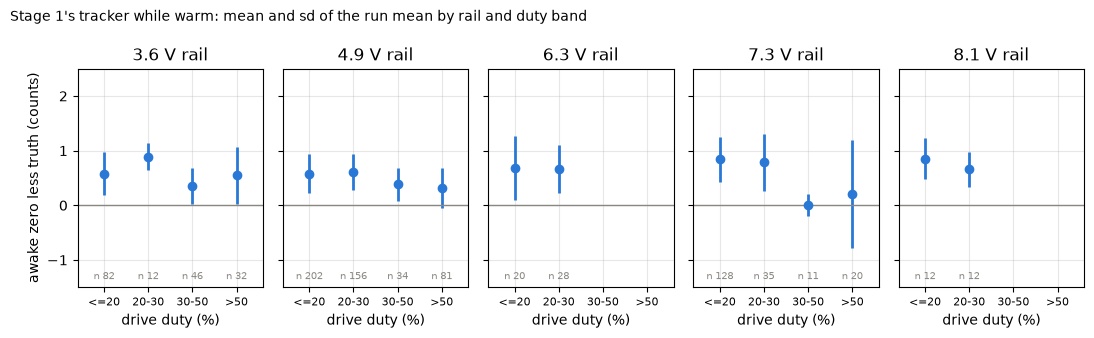

In [12]:
rails = [b for b in RAIL_LABELS if (WARM["band"] == b).sum() >= 4]
fig, axes = plt.subplots(1, len(rails), figsize=(11, 3.4), sharey=True)
duty_band = pd.cut(WARM["duty_pct"], DUTY_BINS, labels=DUTY_LABELS)
for ax, b in zip(axes, rails):
    m = (WARM["band"] == b).to_numpy()
    g = WARM[m].groupby(duty_band[m], observed=False)["err_mean"]
    a = g.agg(["mean", "std", "size"])
    x = np.arange(len(a))
    ok = (a["size"] >= 3).to_numpy()     # a band with 3 runs or more
    ax.errorbar(x[ok], a["mean"][ok], yerr=a["std"][ok], fmt="o",
                color=BLUE, ms=6, lw=2)
    for xi, n in zip(x[ok], a["size"][ok]):
        ax.annotate(f"n {n}", (xi, -1.35), ha="center", color=MUTED,
                    fontsize=7)
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_xticks(x, a.index, fontsize=8)
    ax.set_xlim(-0.6, len(a) - 0.4)
    figures.label(ax, x="drive duty (%)",
                  title=f"{WARM[m]['vbus'].median():.1f} V rail")
axes[0].set_ylabel("awake zero less truth (counts)")
axes[0].set_ylim(-1.5, 2.5)
fig.suptitle("Stage 1's tracker while warm: mean and sd of the run mean "
             "by rail and duty band", x=0.01, ha="left", fontsize=10)
figures.finish(fig)

What you are looking at: each panel is one rail band, each point the mean error of the warm runs in one duty band, the bar one standard deviation between runs. Zero is a tracker that subtracts the truth exactly. The points sit above zero on every rail, and higher on the rails from 6 V up.

### The float form beside the integer port

Stage 1 kept each zero as an integer with 16 fraction bits and took alpha as an arithmetic shift, `delta = ((x << 16) - z) >> 13`. `zero.replay_int` runs that port tick for tick. Both forms are replayed over every row with stage 1's rule and the `age` model, and compared row by row.

In [13]:
Q_INT, K_INT = zr.replay_int(zr.IntRule(), STORE)  # Q16 state, per row
Z_INT = zr.q_to_float(Q_INT)            # the integer state read as counts
Z64, K64, _ = zr.replay(STAGE1_RULE, STORE)
Z32, _, _ = zr.replay(zr.Rule(f32=True), STORE)   # a float32 state
DRIVE_ROWS = STORE.arrays["bridge"] == sweeps.DRIVE
print(f"{ROWS} rows; feed kinds differ on {(K_INT != K64).sum()} rows")


def diff_row(name, d):
    """mean, rms, worst and the 1 to 99 % range of a difference."""
    p01, p99 = np.percentile(d, [1, 99])
    return dict(pair=name, n=len(d), mean=d.mean(),
                rms=np.sqrt((d ** 2).mean()), max=np.abs(d).max(),
                p01=p01, p99=p99)


FLOAT_INT = pd.DataFrame([
    diff_row("float64 less integer state", Z64 - Z_INT),
    diff_row("same, rows that feed the awake zero",
             (Z64 - Z_INT)[K64 == zr.K_AWAKE]),
    diff_row("float64 less integer rounded, drive rows",
             (Z64 - zr.counts(Q_INT))[DRIVE_ROWS]),
    diff_row("float32 state less float64", Z32 - Z64)]).set_index("pair")
print(FLOAT_INT.round(4).to_string())
FLOOR = 0.5 * 2.0 ** -zr.FRAC * 2 ** zr.ALPHA_SHIFT   # counts
print(f"half a Q16 unit per fed tick times 2^13 = {FLOOR:.4f} counts")

22853600 rows; feed kinds differ on 0 rows


                                                 n    mean     rms     max     p01     p99
pair                                                                                      
float64 less integer state                22853600  0.0625  0.0633  0.1041  0.0400  0.0863
same, rows that feed the awake zero       16089639  0.0626  0.0632  0.0994  0.0413  0.0841
float64 less integer rounded, drive rows  10508431  0.0696  0.2990  0.5885 -0.4278  0.5519
float32 state less float64                22853600 -0.0006  0.2208  0.8321 -0.4633  0.4509
half a Q16 unit per fed tick times 2^13 = 0.0625 counts


The feed kind agrees on every row. The float state sits +0.0625 counts above the integer state, rms 0.0633, never more than 0.1041 apart. The mean is the integer port's floor. The shift `>> 13` rounds toward minus infinity and drops half a Q16 unit per fed tick on average, and a loop gain of $2^{13}$ turns that into $2^{-17} \times 2^{13}$ counts, the 0.0625 the data gives. A float32 state is not the float form. At 1200 counts one unit in its last place is $2^{-13}$ counts, the size of the update a one-count error makes, so the state moves in whole steps and sits 0.2208 counts rms from the float64 state, worst 0.8321.

In [14]:
a, e = int(SW["i0"].iat[0]), int(SW["i1"].iat[0])   # the first sweep
arr = STORE.arrays
cut = np.r_[a, a + np.flatnonzero(arr["pre_gap"][a:e] > 0), e]
seed0 = float(round(float(arr["trough"][:zr.ZERO_SETTLE_TICKS].mean())))
state, worst = (seed0, seed0, 0, 0), 0.0
for p, q in zip(cut[:-1], cut[1:]):     # aged across each gap, no feed
    g = int(arr["pre_gap"][p])
    state = (state[0], state[1], max(0, state[2] - g), max(0, state[3] - g))
    ref, state = zr.track(K64[p:q], arr["trough"][p:q].astype(float),
                          *state)
    worst = max(worst, float(np.abs(ref - Z64[p:q]).max()))
print(f"zero.track against the replay, sweep 0: {e - a} rows in "
      f"{len(cut) - 1} pieces, largest difference {worst:.1e} counts")
D_INT = zr.score_int(zr.IntRule(), STORE)
per_run = (D_AGE["err_mean"] - D_INT.loc[D_AGE.index, "err_mean"])
print(f"per run, float less integer: mean {per_run.mean():+.4f}, sd "
      f"{per_run.std():.4f}, worst {per_run.abs().max():.4f}, "
      f"n {len(per_run)}")
I_WARM = zr.classes(D_INT.loc[WARM.index], SW, HALF_COUNT_V, LONG_GAP_S)
for name, w, d in (("float", WARM, D_AGE),
                   ("integer", I_WARM, D_INT.loc[D_AGE.index])):
    print(f"{name:8s} warm rms {zr.stats(w['err_mean'])['rms']:.2f} mean "
          f"{w['err_mean'].mean():+.2f}, all runs rms "
          f"{zr.stats(d['err_mean'])['rms']:.2f}")

zero.track against the replay, sweep 0: 34000 rows in 5 pieces, largest difference 0.0e+00 counts


per run, float less integer: mean +0.0626, sd 0.0087, worst 0.0934, n 975
float    warm rms 0.73 mean +0.58, all runs rms 0.88
integer  warm rms 0.68 mean +0.52, all runs rms 0.84


`zero.track`, the plain per-tick form, equals the replay to the last bit over the first sweep. On the score the port is that constant and nothing else, +0.0626 per run with an sd of 0.0087. The integer port reads 0.68 warm with a mean of +0.52 and 0.84 over all runs, the float form 0.73, +0.58 and 0.88. Every figure below is the float form with a 64-bit state.

A reading that subtracts the rounded zero instead of the zero with its fraction carries a further 0.30 counts rms, 0.2990 on the drive rows above with the worst at 0.5885. That is the size of the constant section 7 takes out, so the reading subtracts the zero with its fraction.

## 3. What may feed it on a servo

### The trough against the coast

Stage 1's tracker feeds the awake zero with the trough sample, the amplifier read in the off part of the period, on drives no wider than 30 % of the period. If the trough carried part of the winding current, a feed under load would pull the zero up with the current. Per drive run, over its second half, three quantities are read against the truth $T$: the winding current $i$, the crest column less $T$, the trough's excess $e$, the trough column less $T$, and the duty $D$ as a fraction of the period.

Most sweeps with a stall or a hold under load end without a long coast and carry no truth. They take a proxy, the sweep's asleep baseline plus the awake step line fitted here on the sweeps that carry both. The rotor state of a run comes from its dataset and its pot. A stall or locked-horn dataset is a stall. In the load experiment a run whose pot moves 8 counts or less over its second half is a loaded hold, otherwise the load is moving. Elsewhere the rotor is free, or a free rig standing still.

In [15]:
STEPS = zr.step_table(SW)               # per sweep: rail, step, day
LINE = results.fit_line(STEPS["rail"], STEPS["step"])
LINE_SD = float(np.sqrt((LINE["resid"] ** 2).sum() / (LINE["n"] - 2)))
print(f"step = {LINE['intercept']:+.2f}({LINE['intercept_se']:.2f}) + "
      f"{LINE['slope']:.3f}({LINE['slope_se']:.3f}) x rail, residual sd "
      f"{LINE_SD:.2f} counts, {LINE['n']} sweeps")
POS_STILL = 8      # pot counts over the second half: a run standing still
d = RUNS[RUNS["kind"] == sweeps.DRIVE].copy()
for col in ("experiment", "day", "ds", "sub", "stall", "sload", "base_raw"):
    d[col] = SW[col].to_numpy()[d["sweep"].to_numpy()]
d["T_src"] = np.where(d["truth"].notna(), "coast", "proxy")
d["T"] = d["truth"].where(d["truth"].notna(), d["base_raw"]
                          + LINE["intercept"] + LINE["slope"] * d["vbus"])
d["D"] = d["duty"] / STORE.pwm_arr      # duty, a fraction of the period
d["i"] = d["raw_s"] - d["T"]            # the winding current, counts
d["e"] = d["trough_s"] - d["T"]         # the trough's excess, counts
still = d["pos_rng_s"] <= POS_STILL
locked = d["stall"] | (d["sload"]
                       & d["experiment"].isin(["resistance", "inductance"]))
d["state"] = np.where(locked, "stall", np.where(
    d["experiment"] == "load",
    np.where(still, "loaded hold", "load moving"),
    np.where(still, "free rig, still", "free")))
DRV = d
print(DRV.groupby(["state", "T_src"]).agg(
    n=("e", "size"), sweeps=("sweep", "nunique"), D=("D", "median"),
    i=("i", "median"), e=("e", "mean"), e_sd=("e", "std")).round(2))

step = -2.72(0.20) + 1.667(0.037) x rail, residual sd 0.70 counts, 243 sweeps
                         n  sweeps     D       i      e    e_sd
state           T_src                                          
free            coast  493     189  0.30  112.92  27.25   85.84
                proxy  198      34  0.30  111.10   0.95    0.45
free rig, still coast  382     187  0.15   89.65  21.79   66.19
                proxy    2       1  0.12  226.64   0.94    1.42
load moving     coast   47      46  0.30  265.62   0.89    0.49
                proxy  198     147  0.27  157.70   1.13    0.39
loaded hold     coast   53      47  0.20  248.83   0.57    1.23
                proxy  248     160  0.20  268.02   1.22    0.50
stall           proxy  149      73  0.24  364.52  68.40  229.19


The proxy step line on this servo is $-2.72 + 1.667\,V$ counts with a residual sd of 0.70 over the 243 sweeps that carry both a truth and a baseline, beside stage 1's $-3.51 + 1.78\,V$ and 0.68. The large means of $e$ in the free groups with a coast truth, 27.25 and 21.79, hold the runs at 100 % duty, where the trough is the current, as the rungs below show. The other groups read 0.57 to 1.22 counts.

In [16]:
RUNG_BINS = [0, .08, .12, .17, .22, .27, .32, .37, .45, .55]   # fraction
pct = (DRV["D"] * 100).round().astype(int)
DRV["rung"] = np.where(DRV["D"] > RUNG_BINS[-1], pct.astype(str) + " %",
                       pd.cut(DRV["D"], RUNG_BINS).astype(str))
hold = DRV["state"].isin(["stall", "loaded hold"])
DRV["grp"] = np.where(hold, "stall+hold",
                      np.where(DRV["state"] == "free", "free", "other"))
RUNGS = (DRV[DRV["e"].notna()]
         .groupby(["grp", "rung"], observed=True)
         .agg(D=("D", "median"), n=("e", "size"), i=("i", "mean"),
              e=("e", "mean"), e_sd=("e", "std"))
         .sort_values(["grp", "D"]).round(2))
print("by duty rung (fraction of the period), groups of 5 runs or more")
print(RUNGS[RUNGS["n"] >= 5].drop(index="other", level="grp").to_string())
full = DRV[DRV["duty"] >= STORE.pwm_arr]           # 100 % duty, no off
print("at 100 % duty, e less i by group:",
      (full["e"] - full["i"]).groupby(full["grp"]).mean().round(2).to_dict())

by duty rung (fraction of the period), groups of 5 runs or more
                            D    n       i       e   e_sd
grp        rung                                          
free       (0.0, 0.08]   0.07   71   74.26    0.89   0.51
           (0.08, 0.12]  0.10   44   72.84    0.56   0.40
           (0.12, 0.17]  0.15   30   86.66    0.66   0.37
           (0.17, 0.22]  0.20  120  110.11    0.77   0.51
           (0.22, 0.27]  0.25   14  114.11    0.84   0.32
           (0.27, 0.32]  0.30  217  118.46    0.87   0.46
           (0.32, 0.37]  0.35    6  120.15    1.23   0.44
           (0.37, 0.45]  0.40  108  130.69    1.06   0.44
           (0.45, 0.55]  0.50    6  159.97    1.48   0.50
           60 %          0.60   18  181.94    1.12   0.47
           67 %          0.67    7  319.63    1.47   0.78
           80 %          0.80    6  144.44    1.06   0.38
           100 %         1.00   44  295.49  296.64  52.65
stall+hold (0.0, 0.08]   0.06   27   82.44    1.34   0.51
        

From 8 to 80 % duty the free rungs read 0.56 to 1.48 counts while the current runs from 73 to 182 counts and, on the stall and hold rungs, to 469. The stall and hold rungs read 0.76 to 1.40 at 12 % and wider, inside the proxy truth's 0.70 of the free ones. At 100 % duty there is no off window and the trough is the current, 840.10 against 839.92 on the stalls and 296.64 against 295.49 on the free runs. Nothing was captured between 80 and 100 %.

In [17]:
def ols(X, y):
    """Least squares y = c0 + X b: coefficients, their se, residual sd."""
    A = np.c_[np.ones(len(y)), X]
    coef = np.linalg.lstsq(A, y, rcond=None)[0]
    r = y - A @ coef
    sd = r.std(ddof=A.shape[1])
    se = sd * np.sqrt(np.diag(np.linalg.inv(A.T @ A)))
    return coef, se, sd


narrow = DRV["D"] <= 0.30
SETS = {"coast truth": (DRV["T_src"] == "coast") & narrow,
        "coast or proxy truth": narrow,
        "free, coast truth": ((DRV["state"] == "free")
                              & (DRV["T_src"] == "coast") & narrow),
        "stall + loaded hold": hold & narrow}
rec = []
for name, m in SETS.items():
    q = DRV[m & DRV["e"].notna()]
    for model, X in (("i", q[["i"]]), ("D", q[["D"]]),
                     ("i + i*D", np.c_[q["i"], q["i"] * q["D"]])):
        cf, se, sd = ols(np.asarray(X, float), q["e"].to_numpy())
        rec.append(dict(set=name, model=model, n=len(q), c0=cf[0],
                        c0_se=se[0], b1=cf[1], b1_se=se[1], resid_sd=sd))
FITS = pd.DataFrame(rec)
print("e = c0 + b1 x (first term), duty 30 % or narrower")
print(FITS.round(4).to_string(index=False))
b_all = FITS.set_index(["set", "model"]).loc[("coast or proxy truth", "i"),
                                             "b1"]
print(f"the share at 400 counts of current: {b_all * 400:.1f} counts")

e = c0 + b1 x (first term), duty 30 % or narrower
                 set   model    n     c0  c0_se      b1  b1_se  resid_sd
         coast truth       i  741 0.4818 0.0775  0.0015 0.0006    0.9333
         coast truth       D  741 0.5283 0.0718  0.6754 0.3468    0.9346
         coast truth i + i*D  741 0.5296 0.0923  0.0003 0.0014    0.9333
coast or proxy truth       i 1266 0.5421 0.0430  0.0018 0.0003    0.7871
coast or proxy truth       D 1266 0.6005 0.0530  1.0530 0.2502    0.7970
coast or proxy truth i + i*D 1266 0.5908 0.0467  0.0002 0.0007    0.7853
   free, coast truth       i  364 0.4323 0.1110  0.0035 0.0010    0.4890
   free, coast truth       D  364 0.7194 0.0637  0.3780 0.2808    0.4954
   free, coast truth i + i*D  364 0.2671 0.1568  0.0065 0.0023    0.4881
 stall + loaded hold       i  308 0.8989 0.1188  0.0005 0.0004    0.6852
 stall + loaded hold       D  308 0.8021 0.1183  1.1636 0.5756    0.6822
 stall + loaded hold i + i*D  308 1.3955 0.1561 -0.0051 0.0013    0.6627
t

Fitted on the current at 30 % duty or narrower, the trough carries 0.0015 of it, $\pm$ 0.0006, against a coast truth, and 0.0018 $\pm$ 0.0003 against the coast or proxy truth. That is 0.7 counts at 400 counts of current. On the stalls and loaded holds alone it is 0.0005 $\pm$ 0.0004, not different from zero. Against the duty instead the excess reads 0.60 + 1.05 $D$ ($\pm$ 0.25). On the coast-truth set the two-term fit leaves the same residual as the current alone, 0.9333, so the data does not say whether the current or the duty carries the slope. The standard errors are not clustered by sweep and are lower bounds. With high confidence the trough carries under 0.3 % of the winding current, with moderate confidence on the value.

In [18]:
sag = DRV[(DRV["experiment"] == "sag") & (DRV["state"] == "stall")
          & (DRV["D"] <= 0.30)]
over_base = sag["trough_s"] - sag["base_raw"]   # trough less asleep, counts
line_there = LINE["intercept"] + LINE["slope"] * sag["vbus"]
print(f"sag stop runs: n {len(sag)}, duty {100 * sag['D'].min():.0f} to "
      f"{100 * sag['D'].max():.0f} %, i {sag['i'].mean():.0f} counts")
print(f"trough less the asleep baseline {over_base.mean():.2f} at "
      f"{sag['vbus'].mean():.2f} V, the step line there "
      f"{line_there.mean():.2f}, e {sag['e'].mean():.2f} "
      f"(sd {sag['e'].std():.2f})")
print("datasets:", sag["ds"].value_counts().to_dict())

sag stop runs: n 13, duty 18 to 25 %, i 371 counts
trough less the asleep baseline 10.48 at 7.00 V, the step line there 8.95, e 1.54 (sd 1.25)
datasets: {'capture-1': 13}


Stage 1's pointer, about 9 counts more trough at a stall, was the awake step at a higher rail. The 13 sag stop runs, 18 to 25 % duty with 371 counts of current, read 10.48 counts of trough over the asleep baseline at 7.00 V. The step line gives 8.95 there, which leaves an excess of 1.54 (sd 1.25), the same constant the free runs carry. Against a coast zero taken at a lower rail the whole 9 counts would look like current.

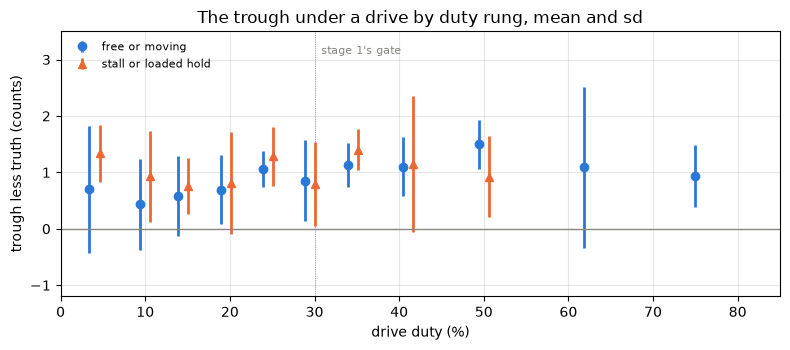

In [19]:
GROUPS = (("free or moving", ~hold, BLUE, "o"),
          ("stall or loaded hold", hold, ORANGE, "^"))
wide_ok = DRV["e"].notna() & (DRV["D"] <= 0.81)    # 80 % and narrower
edges = [0, 8, 12, 17, 22, 27, 32, 37, 45, 55, 70, 81]   # % of the period
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, (name, m, color, mark) in enumerate(GROUPS):
    g = DRV[m & wide_ok]
    a = g.groupby(pd.cut(g["D"] * 100, edges), observed=False)["e"]
    a = a.agg(["mean", "std", "size"])
    ok = (a["size"] >= 5).to_numpy()   # a rung with 5 runs or more
    x = np.array([iv.mid for iv in a.index]) + (k - 0.5) * 1.2
    ax.errorbar(x[ok], a["mean"][ok], yerr=a["std"][ok], fmt=mark,
                color=color, ms=6, lw=2, label=name)
ax.axhline(0, color=MUTED, lw=1)
ax.axvline(zr.GATE_REC_PCT, **figures.EDGE_STYLE)
ax.annotate("stage 1's gate", (zr.GATE_REC_PCT + 0.8, 3.1), color=MUTED,
            fontsize=8)
ax.set_xlim(0, 85)
ax.set_ylim(-1.2, 3.5)
figures.label(ax, x="drive duty (%)", y="trough less truth (counts)",
              title="The trough under a drive by duty rung, mean and sd")
ax.legend(frameon=False, loc="upper left", fontsize=8)
figures.finish(fig)

What you are looking at: the trough's excess $e$ over the zero in the crest column, per duty rung up to 80 %, for free or moving rotors and for stalls and loaded holds, the bar one sd between runs. At 100 % duty there is no off window and the trough is the current, 296.64 and 840.10 counts in the rung table, off the plot. The two groups sit together from 8 to 80 %, flat to within a count while the current grows several times over.

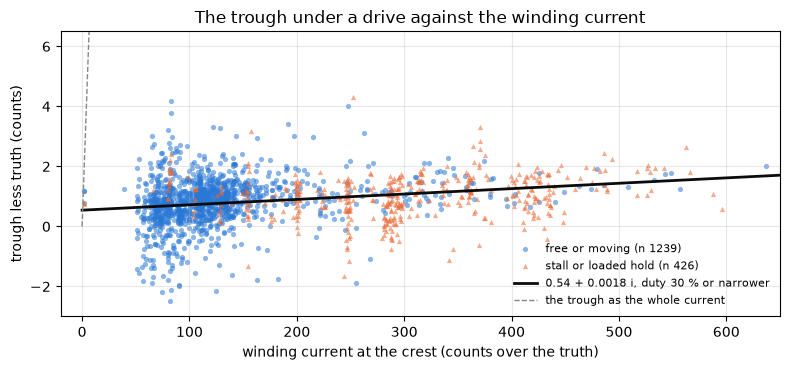

In [20]:
f = FITS[(FITS["set"] == "coast or proxy truth")
         & (FITS["model"] == "i")].iloc[0]
fig, ax = plt.subplots(figsize=(8, 3.8))
for name, m, color, mark in GROUPS:
    g = DRV[m & wide_ok]
    ax.scatter(g["i"], g["e"], s=14, color=color, marker=mark, alpha=0.55,
               linewidths=0, label=f"{name} (n {len(g)})")
x = np.array([0, 650])                  # counts, the current's span
ax.plot(x, f["c0"] + f["b1"] * x, color=INK, lw=2,
        label=f"{f['c0']:.2f} + {f['b1']:.4f} i, duty 30 % or narrower")
ax.plot([0, 6.5], [0, 6.5], color=MUTED, lw=1, ls="--",
        label="the trough as the whole current")
ax.set_xlim(-20, 650)
ax.set_ylim(-3, 6.5)
figures.label(ax, x="winding current at the crest (counts over the truth)",
              y="trough less truth (counts)",
              title="The trough under a drive against the winding current")
ax.legend(frameon=False, loc="lower right", fontsize=8)
figures.finish(fig)

What you are looking at: one point per drive run at 80 % duty or narrower, the trough's excess against the winding current, with the line fitted at 30 % or narrower and, dashed, what a trough carrying the whole current would read. The points stay near the line over the whole span of current, far under the dashed line.

### The feed rule

Candidate rules on the same replay, `age` model. Warm is the 911 warm runs against their coast truth. Moved and cold are the 64 runs of the rail-moved and cold sweeps. Stall and hold are the stall and loaded-hold runs against the coast or proxy truth. Fed is the share of the drive rows, and of all awake rows, that feed the awake zero. The drive-feed offset in the last two rules is this servo's mean $e$ at 30 % duty or narrower, the mean over sweeps of each sweep's mean, in sample here and cross-validated in section 7.

The float tracker carries no current gate and no share term, so the four rules that need one run on the integer port, beside stage 1's rule on the same port. The port's zero sits 0.0625 counts below the float form's, a constant, so its rows compare with each other and the gap between the two stage 1 rows is that constant.

In [21]:
narrow_coast = DRV[(DRV["T_src"] == "coast") & narrow]
DRIVE_OFF_IN = round(float(narrow_coast.groupby("sweep")["e"].mean()
                           .mean()), 2)  # counts, in sample
AWAKE_ROWS = STORE.arrays["bridge"] != sweeps.ASLEEP


def rule_row(name, form, d, kind):
    """Feed shares and the scores of one rule's score table."""
    d = zr.classes(d, SW, HALF_COUNT_V, LONG_GAP_S)
    err_t = d["z_mean"] - DRV.loc[d.index, "T"]   # against coast or proxy
    w, ev = d[d["cls"] == "warm"], d[d["cls"] != "warm"]
    lo, hi = zr.boot_rms(w, "err_mean")
    a, b = zr.stats(w["err_mean"]), zr.stats(ev["err_mean"])
    sh = zr.stats(err_t[hold.loc[d.index]])
    return dict(rule=name, form=form,
                fed_drive=(kind[DRIVE_ROWS] == zr.K_AWAKE).mean(),
                fed_awake=(kind[AWAKE_ROWS] == zr.K_AWAKE).mean(),
                warm_rms=a["rms"], lo=lo, hi=hi, warm_mean=a["mean"],
                warm_sd=a["sd"], warm_n=a["n"], moved_cold_rms=b["rms"],
                moved_cold_n=b["n"], stall_hold_rms=sh["rms"],
                stall_hold_mean=sh["mean"], stall_hold_n=sh["n"])


print(f"drive-feed offset in sample: {DRIVE_OFF_IN:.2f} counts")
GATE30 = zr.gate_ticks(zr.GATE_REC_PCT, STORE.pwm_arr)   # timer ticks
for pct in (zr.GATE_REC_PCT, 80):       # the off window left by a gate
    print(f"gate {pct} %: off window "
          f"{STORE.pwm_arr - zr.gate_ticks(pct, STORE.pwm_arr)} timer ticks")

drive-feed offset in sample: 0.67 counts
gate 30 %: off window 840 timer ticks
gate 80 %: off window 240 timer ticks


In [22]:
off = DRIVE_OFF_IN
FLOAT_RULES = [
    zr.Rule(gate_pct=20, name="duty <= 20 %"),
    zr.Rule(gate_pct=30, name="duty <= 30 % (stage 1)"),
    zr.Rule(gate_pct=40, name="duty <= 40 %"),
    zr.Rule(gate_pct=60, name="duty <= 60 %"),
    zr.Rule(gate_pct=80, name="duty <= 80 %"),
    zr.Rule(gate_pct=0, name="coast + torque off only"),
    zr.Rule(gate_pct=0, coast_raw=True,
            name="coast (crest column) + torque off only"),
    zr.Rule(gate_pct=30, coast_raw=True,
            name="duty <= 30 %, coast feeds the crest column"),
    zr.Rule(gate_pct=30, coast_raw=True, drive_off=off,
            name=f"same, drive feed less {off:.2f}"),
    zr.Rule(gate_pct=80, coast_raw=True, drive_off=off,
            name=f"duty <= 80 %, crest coast, drive less {off:.2f}")]
INT_RULES = [
    zr.IntRule(gate_pct=30, name="duty <= 30 % (stage 1)"),
    zr.IntRule(gate_pct=30, i_gate=150, name="duty <= 30 % and i <= 150"),
    zr.IntRule(gate_pct=30, i_gate=50, name="duty <= 30 % and i <= 50"),
    zr.IntRule(gate_pct=80, i_gate=150, name="duty <= 80 % and i <= 150"),
    zr.IntRule(gate_pct=30, share=0.0015,
               name="duty <= 30 %, feed less 0.0015 i")]
rec = [rule_row(r.name, "float", *zr.score(r, STORE, keep=True)[::2])
       for r in FLOAT_RULES]
rec += [rule_row(r.name, "integer", *zr.score_int(r, STORE, keep=True)[::2])
        for r in INT_RULES]
FEED_RULES = pd.DataFrame(rec)
cols = ["rule", "form", "fed_drive", "fed_awake", "warm_rms", "lo", "hi",
        "warm_mean", "warm_sd", "moved_cold_rms", "stall_hold_rms"]
print(FEED_RULES[cols].round(2).to_string(index=False))
n0 = FEED_RULES.iloc[0]
print(f"runs: warm {n0['warm_n']}, moved + cold {n0['moved_cold_n']}, "
      f"stall + hold {n0['stall_hold_n']}")

                                      rule    form  fed_drive  fed_awake  warm_rms   lo   hi  warm_mean  warm_sd  moved_cold_rms  stall_hold_rms
                              duty <= 20 %   float       0.64       0.78      0.69 0.64 0.73       0.51     0.46            2.47            1.43
                    duty <= 30 % (stage 1)   float       0.85       0.91      0.73 0.68 0.78       0.58     0.44            2.07            1.54
                              duty <= 40 %   float       0.95       0.97      0.75 0.70 0.80       0.62     0.43            2.00            1.30
                              duty <= 60 %   float       0.99       0.99      0.76 0.71 0.80       0.62     0.43            2.01            1.33
                              duty <= 80 %   float       0.99       0.99      0.75 0.71 0.80       0.63     0.41            1.87            1.33
                   coast + torque off only   float       0.00       0.40      0.59 0.53 0.64       0.33     0.48            3.06  

In [23]:
for name in ("duty <= 30 % (stage 1)", "duty <= 30 % and i <= 150"):
    x = FEED_RULES[FEED_RULES["rule"] == name].iloc[-1]
    print(f"{name}: fed {100 * x['fed_drive']:.0f} % of drive rows, "
          f"{100 * x['fed_awake']:.0f} % of awake rows")
print(f"sweeps with no long coast: {SW['truth'].isna().sum()}; off window "
      f"at 30 % less at 80 %: {zr.gate_ticks(80, STORE.pwm_arr) - GATE30} "
      "ticks")

duty <= 30 % (stage 1): fed 85 % of drive rows, 91 % of awake rows
duty <= 30 % and i <= 150: fed 62 % of drive rows, 77 % of awake rows
sweeps with no long coast: 277; off window at 30 % less at 80 %: 600 ticks


Every rule leaves the same scatter, an sd of 0.40 to 0.49 counts. The rules differ in how much of the constant they let in. No gate width from 20 to 80 % separates from another by error, 0.69 to 0.76 warm with overlapping brackets. A current gate buys nothing, 0.65 against 0.68 on the integer port inside the bracket, and costs feed time, 85 % of the drive rows down to 62 %, and the stall and hold score, 1.49 up to 1.70. Coast and torque off only score well while warm, 0.59, but feed no drive row. 277 of the 521 sweeps have no long coast, and after a rail move or a cold start this rule is the worst, 3.06 counts rms over 64 runs. The one change that moves the score takes the constant out. The coast fed from the crest column and the drive feed less its own offset take the warm rms from 0.73 to 0.42, bracket 0.37 to 0.47, in sample.

The feed rule is the duty gate alone at 30 %, a settled coast and torque off, with no current gate. The trough is clean to 80 % duty, so a wider gate is supported by the data. The gate stays at 30 % because the feed is plentiful there, 85 % of the drive rows and 91 % of the awake rows. In ticks, a gate of 30 % leaves an off window of 840 timer ticks and the widest rung verified clean leaves 240, 600 ticks less. The floor of the off window is a board quantity, the window the amplifier needs to settle, and it lies somewhere under 240 ticks.

### The two columns

The zero is learned in the trough column and the reading subtracts it from the crest column. The two columns are read with no current twice. Asleep, the baseline's trough less its crest. Awake, a coast tail's trough less its crest, averaged per sweep. Then the trough under a narrow drive is compared with the trough of the same sweep's coast tail.

In [24]:
SW["band"] = rail_band(SW["rail"])
asleep = SW.assign(off=SW["base_trough"] - SW["base_raw"])
tails = RUNS[(RUNS["kind"] == sweeps.COAST) & RUNS["tail_raw"].notna()]
tails = tails.assign(off=tails["tail_trough"] - tails["tail_raw"])
coast = (tails.groupby("sweep").agg(off=("off", "mean"),
                                    tt=("tail_trough", "mean"))
         .join(SW[["band", "day", "rail"]]))
rec = []
for state, x in (("asleep", asleep), ("coast tail", coast)):
    rec.append(dict(state=state, by="all", key="all", mean=x["off"].mean(),
                    sd=x["off"].std(), n=x["off"].notna().sum()))
    for by in ("band", "day"):
        g = x.groupby(by, observed=True)["off"]
        rec += [dict(state=state, by=by, key=str(k), mean=v.mean(),
                     sd=v.std(), n=len(v)) for k, v in g]
OFFSETS = pd.DataFrame(rec)
print(OFFSETS.pivot_table(index=["by", "key"], columns="state",
                          values="mean", sort=False).round(3).to_string())
print(OFFSETS[OFFSETS["by"] == "all"].round(3).to_string(index=False))
slope = np.polyfit(coast["rail"].dropna(),
                   coast["off"][coast["rail"].notna()], 1)[0]
print(f"coast offset on the rail: {slope:+.3f} counts/V")

state         asleep  coast tail
by   key                        
all  all       0.231       0.340
band 3.6       0.160       0.293
     4.9       0.247       0.331
     6.0-6.8   0.224       0.398
     7.0-7.6   0.208       0.396
     >7.8      0.254       0.373
day  11-06     0.187       0.342
     11-07     0.161       0.268
     11-08     0.202       0.357
     11-09     0.280       0.347
     state  by key  mean    sd   n
    asleep all all 0.231 0.111 521
coast tail all all 0.340 0.057 244
coast offset on the rail: +0.026 counts/V


With no current the trough column sits +0.340 counts above the crest column awake, sd 0.057 between 244 sweeps, 0.27 to 0.36 by day and 0.29 to 0.40 by rail. Asleep it sits +0.231 above, sd 0.111 over 521 sweeps, 0.16 to 0.28 by day. The awake offset grows by +0.026 counts per volt.

In [25]:
q = DRV[(DRV["T_src"] == "coast") & narrow].copy()
q["rise"] = q["trough_s"] - coast["tt"].reindex(q["sweep"]).to_numpy()
q["band"] = rail_band(q["vbus"])
r = q.groupby("sweep")["rise"].mean()
RISE = (r.mean(), r.std(), r.std() / np.sqrt(len(r)), len(r))
print("trough under a drive of 30 % or narrower less the trough in the "
      "same sweep's coast tail:")
print(f"mean {RISE[0]:+.2f}, sd {RISE[1]:.2f} between sweeps, se "
      f"{RISE[2]:.2f}, {RISE[3]} sweeps")
print("by rail:", q.groupby("band", observed=True)["rise"].mean()
      .round(2).to_dict())
print("by rotor state:", q.groupby("state")["rise"].mean().round(2)
      .to_dict())
TROUGH1 = COMP1["motor_trough"]["over_coast_same_column_counts"]
print("stage 1's motor rig, the same quantity:",
      {k: round(v["value"], 2) for k, v in TROUGH1.items()})

trough under a drive of 30 % or narrower less the trough in the same sweep's coast tail:
mean +0.32, sd 0.53 between sweeps, se 0.04, 186 sweeps
by rail: {'3.6': 0.19, '4.9': 0.22, '6.0-6.8': 0.41, '7.0-7.6': 0.5, '>7.8': 0.68}
by rotor state: {'free': 0.44, 'free rig, still': 0.12, 'load moving': 0.45, 'loaded hold': 0.31}
stage 1's motor rig, the same quantity: {'3v7': 0.12, '5v0': 0.32, '7v4': 0.35}


Under a narrow drive the trough sits a further +0.32 counts above its coast level, se 0.04 over 186 sweeps. It grows with the rail, 0.19 at 3.6 V to 0.68 over 7.8 V, and reads 0.31 to 0.45 on free, lifting and holding rotors. Stage 1's motor rig read 0.12, 0.32 and 0.35 at its three rails for the same quantity. Confidence is high for the mean and moderate for the trend on the rail.

A zero learned from the trough therefore reads 0.34 counts above the crest-column zero where a coast feeds it and about 0.66 where a narrow drive feeds it. The reading, the crest less the awake zero, is low by that, the +0.58 of section 2. The servo can measure both parts itself with no typed number. The column offset is in any coast, both columns with no current. The drive offset is the trough of a narrow drive less the crest of the coast that follows. Feeding the coast from the crest column removes the first part with no constant at all. Section 7 cross-validates the second.

## 4. Start-up and the rail step

### The error against fed time

An event is a cold or rail-moved sweep that carries a truth, 18 sweeps, 8 cold and 10 rail moved. The state carries, so each event is followed through its own sweep and up to three warm sweeps after it, each scored against its own truth. The error is the float awake zero less the sweep's truth less the warm asymptote, the mean warm error of the same replay, so that a closed start reads zero. The start error $e_0$ is the error at the event's first drive row. Fed time is the time of the rows that fed the awake zero. The tracker is linear, so a start error should close as $e_0\,e^{-t/\tau}$ in fed time $t$, with $\tau = 2^{13}$ ticks, and reach a threshold $h$ after $\tau \ln(|e_0| / h)$.

In [26]:
WINDOW = 4                  # sweeps followed per event, the event's included
EVENTS = np.flatnonzero((SW["cls"] != "warm").to_numpy()
                        & SW["truth"].notna().to_numpy())
BRIDGE, FS = STORE.arrays["bridge"], STORE.tick_hz
FIRST_DUTY = (RUNS[RUNS["kind"] == sweeps.DRIVE].groupby("sweep")["duty"]
              .first().reindex(range(len(SW))).to_numpy())   # timer ticks


def followed(s):
    """Rows a..e of event sweep s and the warm sweeps after it."""
    last, cls, truth = s, SW["cls"].to_numpy(), SW["truth"].to_numpy()
    while (last + 1 < len(SW) and last + 1 - s < WINDOW
           and cls[last + 1] == "warm" and np.isfinite(truth[last + 1])):
        last += 1
    T = np.repeat(truth[s:last + 1], SW["rows"].to_numpy()[s:last + 1])
    return int(SW["i0"].iat[s]), int(SW["i1"].iat[last]), T


def passage(err, fed, k0, e0, thr):
    """Fed s from row k0 to the first row within thr, and the model's."""
    j = k0 + np.flatnonzero(np.abs(err[k0:]) <= thr)
    got = float(fed[j[0]] - fed[k0]) if len(j) else np.nan
    model = TAU_S * np.log(abs(e0) / thr) if abs(e0) > thr else 0.0
    return got, model


print(f"{len(EVENTS)} events:",
      SW["cls"].to_numpy()[EVENTS].tolist().count("cold"), "cold,",
      SW["cls"].to_numpy()[EVENTS].tolist().count("rail moved"),
      "rail moved")

18 events: 8 cold, 10 rail moved


In [27]:
def curves(rule, b_warm=None, skip=0):
    """Per event: e0 and the fed time to 1 and 0.5 counts, and its curve
    of error against fed time. skip: rows past the first drive row."""
    d, out, kind = zr.score(rule, STORE, keep=True)
    d = zr.classes(d, SW, HALF_COUNT_V, LONG_GAP_S)
    if b_warm is None:                  # the warm asymptote of this replay
        b_warm = float(d[d["cls"] == "warm"]["err_mean"].mean())
    rec, cur = [], []
    for s in EVENTS:
        a, e, T = followed(s)
        aw = np.flatnonzero(BRIDGE[a:e] != sweeps.ASLEEP)   # awake rows
        fed = np.cumsum(kind[a:e] == zr.K_AWAKE)[aw] / FS   # fed s
        err = (out[a:e] - T)[aw] - b_warm
        dr0 = np.flatnonzero(BRIDGE[a:e][aw] == sweeps.DRIVE)
        k0 = int(dr0[0]) + skip if len(dr0) else 0
        e0 = float(err[k0])
        ff = np.flatnonzero(np.diff(np.r_[0, fed]) > 0)
        r = dict(sweep=int(s), cls=SW["cls"].iat[s],
                 rail_from=SW["rail"].shift(1).iat[s], rail=SW["rail"].iat[s],
                 first_duty_pct=100 * FIRST_DUTY[s] / STORE.pwm_arr, e0=e0,
                 awake_s_before_feed=ff[0] / FS if len(ff) else np.nan,
                 gap_s=SW["gap_s"].iat[s])
        for thr in (1.0, 0.5):
            r[f"fed_s_to_{thr:g}"], r[f"model_s_to_{thr:g}"] = passage(
                err, fed, k0, e0, thr)
        rec.append(r)
        grid = fed[k0] + np.arange(0, min(fed[-1] - fed[k0], 3.0), 0.01)
        g = np.maximum(k0, np.searchsorted(fed, grid))
        cur.append(pd.DataFrame(dict(sweep=int(s), fed_s=fed[g] - fed[k0],
                                     err=err[g])))
    return pd.DataFrame(rec), pd.concat(cur), b_warm


EV, CUR, B_WARM = curves(STAGE1_RULE)
print(f"warm asymptote {B_WARM:+.3f} counts, tau {TAU_S:.4f} s")
print(EV.drop(columns="gap_s").round(2).to_string(index=False))

warm asymptote +0.584 counts, tau 0.4096 s
 sweep        cls  rail_from  rail  first_duty_pct    e0  awake_s_before_feed  fed_s_to_1  model_s_to_1  fed_s_to_0.5  model_s_to_0.5
     0       cold        NaN  4.92            30.0 -6.36                 0.00        0.86          0.76          1.77            1.04
    13 rail moved       4.84  3.62            15.0  3.01                 0.00        0.37          0.45          0.63            0.74
    28 rail moved       3.64  4.92            15.0 -3.40                 0.00        0.43          0.50          0.72            0.78
    43 rail moved       4.95  7.32            15.0 -3.43                 0.00        0.55          0.50          0.86            0.79
    58 rail moved       7.36  3.63            40.0  6.25                 0.15        0.62          0.75          0.85            1.03
    76 rail moved       3.62  4.92            30.0 -3.76                 0.00        0.55          0.54          1.23            0.83
    94 rail moved  

The tracker's warm asymptote is +0.584 counts, the constant of section 3 plus nothing else. Twelve events open more than 1.5 counts off. Each start error is the step the zero does not know. After a rail move it is the change of the awake step, 2.9 to 3.8 counts between 3.6 and 4.9 V and between 4.9 and 7.3 V, 6.2 to 6.9 between 3.6 and 7.3 V. At boot, with both zeros seeded at the first rows' trough, the asleep level, it is the whole step, -6.36 at 4.92 V. Confidence is high.

In [28]:
BIG = EV[EV["e0"].abs() > 1.5]          # the events with a start error
for thr in ("1", "0.5"):
    x, m = BIG[f"fed_s_to_{thr}"], BIG[f"model_s_to_{thr}"]
    print(f"to within {thr} count: fed s median {x.median():.2f} "
          f"({x.min():.2f} to {x.max():.2f}), model {m.median():.2f} "
          f"({m.min():.2f} to {m.max():.2f}), measured less model "
          f"{(x - m).mean():+.2f} sd {(x - m).std():.2f}, n {len(x)}")
cv = COMP1["convergence"]["settle_within_half_count_s"]
steps1 = [v["value"] for k, v in cv.items() if "boot" not in k]
boots1 = [v["value"] for k, v in cv.items() if "boot" in k]
print(f"stage 1 to half a count: {min(steps1):.2f} to {max(steps1):.2f} s "
      f"for a rail step, {min(boots1):.2f} to {max(boots1):.2f} s at boot")
small = EV[EV["e0"].abs() <= 1.5]
print("events opening within 1.5 counts:",
      [(int(r.sweep), r.cls, round(r.e0, 2), round(r.gap_s / 60))
       for r in small.itertuples()], "(sweep, class, e0, rest in min)")
wide = EV["first_duty_pct"] > zr.GATE_REC_PCT
print(f"events whose first drive is wider than the gate: {wide.sum()} of "
      f"{len(EV)}, sweeps {EV.loc[wide, 'sweep'].tolist()}")

to within 1 count: fed s median 0.54 (0.25 to 0.86), model 0.50 (0.44 to 0.79), measured less model -0.03 sd 0.09, n 12
to within 0.5 count: fed s median 0.78 (0.39 to 1.77), model 0.79 (0.72 to 1.08), measured less model +0.08 sd 0.35, n 12
stage 1 to half a count: 0.82 to 1.13 s for a rail step, 0.71 to 1.25 s at boot
events opening within 1.5 counts: [(201, 'cold', 1.49, 20), (216, 'cold', 0.16, 121), (241, 'cold', 0.58, 161), (298, 'cold', 0.42, 1040), (299, 'cold', -0.42, 64), (374, 'cold', -0.19, 55)] (sweep, class, e0, rest in min)
events whose first drive is wider than the gate: 3 of 18, sweeps [58, 139, 145]


The start errors close as the model says. To within one count the median is 0.54 s of feed, 0.25 to 0.86 over the 12 events, against the model's 0.50, measured less model -0.03 s with an sd of 0.09. To within half a count the median is 0.78 s, 0.39 to 1.77, against 0.79, measured less model +0.08 s with an sd of 0.35. Half a count is about one sd of the warm scatter, so that first passage scatters itself. Stage 1 read 0.82 to 1.13 s for a rail step and 0.71 to 1.25 s at boot. Confidence is high for one count and moderate for half a count.

A long rest alone is not a start. Five cold sweeps on an unchanged rail, after rests of 55 minutes to 17 hours with both zeros stale and the awake zero carried on the asleep zero's moves, open within 0.6 counts. The step the tracker learned holds across hours, and what a rest loses is the rail. With n = 5, confidence is moderate.

Only 3 of the 18 events open on a drive wider than the gate, sweeps 58, 139 and 145. The other start errors of 3 to 4.4 counts open on a drive that feeds. The error is there on the first row whatever the gate, and the gate decides only whether it decays inside the run. The large run-mean errors of section 2 are the three unfed openings and the boot.

### The awake step against the rail

A start rule needs the step at the rail it finds. The step of a sweep is its coast truth less its asleep baseline, both in the crest column, 243 sweeps. `zero.step_fits` fits the step as a line in the rail and as a curve $a + bV + cV^2$, in sample and with each sweep's group left out, by day or by capture set, an experiment's dataset.

In [29]:
FITS_STEP = {(by, deg): zr.step_fits(SW, by, deg)
             for by in (None, "day", "set") for deg in (1, 2)}
rec = []
for (by, deg), (_, folds, t) in FITS_STEP.items():
    r = t["res_out"].dropna()           # in sample when by is None
    rec.append(dict(by=str(by), shape="line" if deg == 1 else "curve",
                    rms=np.sqrt((r ** 2).mean()), n=len(r),
                    sd_in_sample=folds["sd_fit"].iat[0]))
print(pd.DataFrame(rec).round(3).to_string(index=False))
day_folds = FITS_STEP[("day", 1)][1]
print(day_folds[["fold", "n_fit", "c1", "rail_span_fit", "out_mean",
                 "out_sd", "n_out"]].round(2).to_string(index=False))
print("curve held out by day:",
      FITS_STEP[("day", 2)][1]["out_mean"].abs().max().round(1),
      "counts off at worst on a fold")

  by shape    rms   n  sd_in_sample
None  line  0.698 243         0.701
None curve  0.422 243         0.425
 day  line  0.848 243         0.701
 day curve 34.084 243         0.425
 set  line  0.733 243         0.701
 set curve  0.437 243         0.425
         fold  n_fit   c1  rail_span_fit  out_mean  out_sd  n_out
          all    243 1.67            NaN       NaN     NaN      0
without 11-06     99 1.81           0.22     -0.60    0.80    144
without 11-07    230 1.67           4.70      0.31    0.36     13
without 11-08    229 1.67           4.70      0.21    0.47     14
without 11-09    171 1.70           4.70      0.48    0.37     72
curve held out by day: 30.6 counts off at worst on a fold


By day the shape is not held out. Only 11-06 has a truth at any rail but 4.9 V, and the other three days hold 13, 14 and 72 sweeps, all at 4.9 V. The fold without 11-06 fits a line over 0.22 V of rail, and its slope of 1.81 is luck. The curve's fold without 11-06 diverges, 34 counts rms. The other three folds test only the level at 4.9 V, where the line reads the step 0.21 to 0.48 counts low, sd 0.36 to 0.47. So the shape is held out by capture set, 30 sets with a truth, each sweep's shape fitted on the other 29. The line's held-out residual is 0.733 counts rms against 0.698 in sample, the curve's 0.437 against 0.422. That holds out sessions of one day, not days. Confidence that the level at 4.9 V transfers across days is moderate, to half a count. The shape off 4.9 V is untested across days.

In [30]:
t = FITS_STEP[("set", 1)][2].copy()
t["band"] = rail_band(t["rail"])
t["res_curve"] = FITS_STEP[("set", 2)][2]["res_out"]
STEP_BY_RAIL = t.groupby("band", observed=True).agg(
    n=("step", "size"), rail=("rail", "mean"), step=("step", "mean"),
    step_sd=("step", "std"), line_res=("res_out", "mean"),
    line_res_sd=("res_out", "std"), curve_res=("res_curve", "mean"),
    curve_res_sd=("res_curve", "std"))
print(STEP_BY_RAIL.round(2).to_string())
off49 = t[(t["rail"] < 4.2) | (t["rail"] > 5.6)]
print("days with a truth off 4.9 V:", sorted(off49["day"].unique()),
      "| capture sets with a truth:",
      (SW["experiment"] + "/" + SW["ds"])[t["sweep"]].nunique())
two = COMP1["step_shape"]["two_point_slopes_counts_per_v"]
print("stage 1's two-point slopes:",
      {k: round(v["value"], 2) for k, v in two.items()}, "counts/V")

           n  rail  step  step_sd  line_res  line_res_sd  curve_res  curve_res_sd
band                                                                             
3.6       39  3.63  2.42     0.29     -1.05         0.29       0.13          0.33
4.9      145  4.90  5.77     0.37      0.30         0.36      -0.06          0.37
6.0-6.8   10  6.32  9.25     0.48      1.35         0.82       1.06          0.70
7.0-7.6   44  7.32  9.12     0.37     -0.40         0.42      -0.08          0.36
>7.8       5  8.08  9.33     0.27     -1.63         0.19      -0.07          0.27
days with a truth off 4.9 V: ['11-06'] | capture sets with a truth: 30
stage 1's two-point slopes: {'3v7_to_5v0': 2.58, '5v0_to_7v4': 1.48} counts/V


The line is the wrong shape. The step climbs from 2.42 counts at 3.6 V to 5.77 at 4.9 V and is flat from 6 V up, 9.25, 9.12 and 9.33. The line's held-out residuals by rail are -1.05, +0.30, +1.35, -0.40 and -1.63, each many of its sd from zero. Stage 1 saw the same on the motor rig, two-point slopes of 2.58 and 1.48 counts/V. The curve's residuals are +0.13, -0.06, -0.08 and -0.07 on four bands. The 6.0-6.8 V band, the sag's 10 sweeps, sits +1.06 above even the curve. A line through a curve takes its slope from where the sweeps sit, and 145 of the 243 sit at 4.9 V. That is most likely the reason this servo's slope of 1.667 differs from stage 1's 1.78.

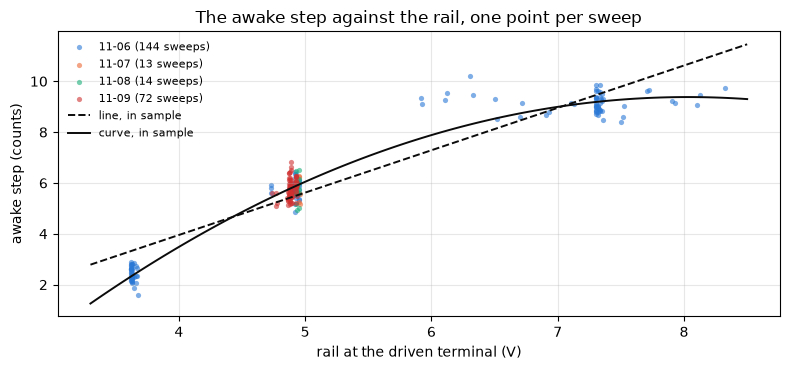

In [31]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for day, color in zip(sorted(t["day"].unique()), (BLUE, ORANGE, GREEN, RED)):
    g = t[t["day"] == day]
    ax.scatter(g["rail"], g["step"], s=14, color=color, alpha=0.6,
               linewidths=0, label=f"{day} ({len(g)} sweeps)")
v = np.linspace(3.3, 8.5, 100)          # V, the rails captured
for (by, deg), style in (((None, 1), "--"), ((None, 2), "-")):
    co = FITS_STEP[(by, deg)][1].iloc[0]
    y = sum(co.get(f"c{i}", 0.0) * v ** i for i in range(deg + 1))
    ax.plot(v, y, color=INK, lw=1.4, ls=style,
            label=("line" if deg == 1 else "curve") + ", in sample")
figures.label(ax, x="rail at the driven terminal (V)",
              y="awake step (counts)",
              title="The awake step against the rail, one point per sweep")
ax.legend(frameon=False, loc="upper left", fontsize=8)
figures.finish(fig)

What you are looking at: the awake step of every sweep with a truth against its rail, colored by day, with the line and the curve fitted in sample. The points off 4.9 V are all from 11-06, so the curve's shape off 4.9 V rests on one capture day. The step rises steeply below 5 V and levels off above 6 V.

### The start rule and its threshold

A rule may use what the servo has, the asleep zero, the rail, the step shape and its own stale flag. In these rows the rail exists only inside a drive, so every rule acts at a drive row. A rail move counts once it has held for 32 rail rows, the tracker's own settle ticks, and the seed takes their mean. The seed is `zero.seed_awake`, the asleep zero plus the step shape at the rail.

The threshold comes from the servo's own numbers. Seeding costs the shape's residual. Holding costs the held zero's scatter plus the slope times the rail move. So a seed pays when $b\,\Delta V > \sqrt{s_{shape}^2 - s_{held}^2}$, `zero.seed_threshold_v`. The slope $b$ is the line's in sample, $s_{shape}$ the line's held-out residual by capture set, and $s_{held}$ the sd of the error on the first drive row of a warm sweep, the zero held stale across the rest.

In [32]:
def held_sd():
    """sd of the held awake zero at the first row of a warm sweep."""
    w = D_AGE[(D_AGE["cls"] == "warm") & D_AGE["first_in_sweep"]]
    return float(w["err_first"].std()), int(w["err_first"].notna().sum())


def seeded(by, deg, **kw):
    """A float rule with the step shape fitted with its group left out."""
    a, b, c = FITS_STEP[(by, deg)][0]
    return zr.Rule(step_a=a, step_b=b, step_c=c, **kw)


SD_HELD, N_HELD = held_sd()
res_set = FITS_STEP[("set", 1)][2]["res_out"].dropna()
SD_LINE = float(np.sqrt((res_set ** 2).mean()))   # held out by set
SLOPE = float(FITS_STEP[(None, 1)][0][1][0])       # counts/V, in sample
THR_V = zr.seed_threshold_v(SLOPE, SD_LINE, SD_HELD)
START = dict(seed_boot=True, seed_thr_v=THR_V)     # boot and rail moved
CHOSEN = seeded("set", 1, **START, name="seed at boot + rail moved")
print(f"slope {SLOPE:.3f} counts/V, line held out {SD_LINE:.3f}, held zero "
      f"sd {SD_HELD:.3f} (n {N_HELD}) -> threshold {THR_V:.2f} V")

slope 1.667 counts/V, line held out 0.733, held zero sd 0.505 (n 226) -> threshold 0.32 V


In [33]:
def paired(d, base, col="err_mean", n=2000, seed=1):
    """rms of d less rms of base over the same runs, with its 95 %
    bracket from resampling sweeps."""
    m = d[col].notna() & base[col].notna()
    g = pd.DataFrame(dict(sweep=d["sweep"][m], a=d[col][m] ** 2,
                          b=base[col][m] ** 2)).groupby("sweep").agg(
        a=("a", "sum"), b=("b", "sum"), n=("a", "size"))
    if len(g) < 4:
        return np.nan, np.nan, np.nan
    idx = np.random.default_rng(seed).integers(0, len(g), (n, len(g)))
    A, B, N = (g[k].to_numpy()[idx].sum(1) for k in ("a", "b", "n"))
    lo, hi = np.percentile(np.sqrt(A / N) - np.sqrt(B / N), [2.5, 97.5])
    full = np.sqrt(g["a"].sum() / g["n"].sum())
    return float(full - np.sqrt(g["b"].sum() / g["n"].sum())), lo, hi


def classed(rule):
    """The rule's score table with classes, and its seeds per sweep."""
    d = zr.score(rule, STORE)
    return zr.classes(d, SW, HALF_COUNT_V, LONG_GAP_S), d.attrs["n_seed"]


BASE = zr.classes(zr.score(STAGE1_RULE, STORE), SW, HALF_COUNT_V,
                  LONG_GAP_S)
print("paired against stage 1's rule over the same runs")

paired against stage 1's rule over the same runs


In [34]:
def start_row(rule, base=BASE):
    """One rule: warm and event scores, paired against base."""
    d, ns = classed(rule)
    w, ev = d[d["cls"] == "warm"], d[d["cls"] != "warm"]
    bw, bev = base[base["cls"] == "warm"], base[base["cls"] != "warm"]
    a, b = zr.stats(w["err_mean"]), zr.stats(ev["err_mean"])
    f = zr.stats(ev[ev["first_in_sweep"]]["err_start"])
    fed1 = (FIRST_DUTY[ev["sweep"].to_numpy()]
            <= zr.gate_ticks(rule.gate_pct, STORE.pwm_arr))
    dw, ev_ = paired(w, bw), paired(ev, bev)
    wb, eb = zr.boot_rms(w, "err_mean"), zr.boot_rms(ev, "err_mean")
    fd, ufd = zr.stats(ev[fed1]["err_mean"]), zr.stats(ev[~fed1]["err_mean"])
    cls = SW["cls"].to_numpy()
    return dict(rule=rule.name, warm_rms=a["rms"], warm_lo=wb[0],
                warm_hi=wb[1], warm_mean=a["mean"], d_warm=dw[0],
                d_warm_lo=dw[1], d_warm_hi=dw[2], ev_rms=b["rms"],
                ev_lo=eb[0], ev_hi=eb[1], ev_worst=b["worst"], d_ev=ev_[0],
                d_ev_lo=ev_[1], d_ev_hi=ev_[2], start_rms=f["rms"],
                start_mean=f["mean"], start_worst=f["worst"],
                fed_first=fd["rms"], unfed_first=ufd["rms"],
                seeds_warm=int((ns[cls == "warm"] > 0).sum()),
                n_warm=a["n"], n_ev=b["n"], n_start=f["n"], n_fed=fd["n"],
                n_unfed=ufd["n"])

In [35]:
FAST10 = dict(fast_shift=10, fast_n=4 << 10)       # 2^-10 for 4096 ticks
MEAN256 = dict(fast_n=256, fast_mean=True)        # gain 1 / (256 + n)
START_RULES = [
    zr.Rule(name="stage 1, no start rule"),
    seeded("set", 1, seed_boot=True, name="seed at boot only (line)"),
    CHOSEN,
    seeded("set", 1, **START, debounce=1, name="same, move on one rail row"),
    seeded("day", 1, **START, name="same, line by day"),
    seeded(None, 1, **START, name="same, line in sample"),
    seeded("set", 2, **START, name="seed at boot + rail moved (curve)"),
    seeded("set", 1, **START, seed_stale=True,
           name="seed at boot + stale + rail moved (line)"),
    seeded("set", 2, **START, seed_stale=True,
           name="seed at boot + stale + rail moved (curve)"),
    seeded("set", 1, **START, shift_only=True,
           name="boot, shift by the slope on a move (line)"),
    seeded("set", 1, seed_boot=True, ff=True,
           name="boot, shape fed forward every row (line)"),
    seeded("set", 2, seed_boot=True, ff=True, name="same (curve)"),
    zr.Rule(**FAST10, fast_on="stale", name="fast 2^-10, 4096 ticks, stale"),
    zr.Rule(fast_shift=11, fast_n=4 << 11, fast_on="stale",
            name="fast 2^-11, 8192 ticks, stale"),
    zr.Rule(**MEAN256, fast_on="stale", name="running mean, stale"),
    zr.Rule(seed_thr_v=THR_V, no_seed=True, **FAST10, fast_on="seed",
            name="no seed, fast 2^-10 after a move"),
    seeded("set", 1, **START, **FAST10, fast_on="seed",
           name="seed, then fast 2^-10 (line)"),
    seeded("set", 1, **START, **MEAN256, fast_on="seed",
           name="seed, then running mean (line)"),
    seeded("set", 1, **START, **FAST10, fast_on="both",
           name="fast after a seed or stale (line)")]
RULES_T = pd.DataFrame([start_row(r) for r in START_RULES])

In [36]:
cols = ["rule", "warm_rms", "warm_lo", "warm_hi", "d_warm", "d_warm_lo",
        "d_warm_hi", "ev_rms", "ev_lo", "ev_hi", "ev_worst", "start_rms",
        "fed_first", "unfed_first"]
print(RULES_T[cols].round(3).to_string(index=False))
r0 = RULES_T.iloc[0]
print(f"runs: warm {r0['n_warm']}, events {r0['n_ev']} (first drive fed "
      f"{r0['n_fed']}, not fed {r0['n_unfed']}), event starts "
      f"{r0['n_start']}")

                                     rule  warm_rms  warm_lo  warm_hi  d_warm  d_warm_lo  d_warm_hi  ev_rms  ev_lo  ev_hi  ev_worst  start_rms  fed_first  unfed_first
                   stage 1, no start rule     0.730    0.684    0.778   0.000      0.000      0.000   2.070  1.363  2.636     7.204      3.775      1.387        3.565
                 seed at boot only (line)     0.730    0.684    0.778   0.000     -0.001      0.001   1.977  1.224  2.570     7.204      3.500      1.203        3.565
                seed at boot + rail moved     0.727    0.678    0.775  -0.004     -0.028      0.019   0.640  0.511  0.754     1.648      0.663      0.606        0.750
               same, move on one rail row     0.724    0.675    0.774  -0.007     -0.033      0.019   0.691  0.564  0.804     1.801      0.740      0.624        0.889
                        same, line by day     0.741    0.689    0.795   0.011     -0.018      0.040   0.685  0.558  0.791     1.588      0.777      0.643        0.81

The rules run on the float tracker with the 30 % gate and the `age` model. Warm is 911 runs in 226 sweeps. The events are 64 runs in 17 sweeps, 50 of them in sweeps whose first drive feeds and 14 in the three whose first drive does not. The start error is read 5 ms into the event sweep's first drive, past any seed, 17 starts. The brackets come from resampling sweeps, and "less stage 1" is paired over the same runs.

Seeding the awake zero at the asleep zero plus the step line at the measured rail, at boot and whenever the rail has moved more than 0.32 V from where the zero was learned, takes the events from 2.070 to 0.640 counts rms, bracket 0.511 to 0.754. The worst falls from 7.204 to 1.648 and the start error from 3.775 to 0.663. The warm score stays where it was, -0.004 paired, bracket -0.028 to +0.019. After the seed an event sweep scores like a warm one, 0.640 against 0.727. The three hold-outs of the line agree, 0.629 in sample, 0.640 by capture set and 0.685 by day.

Seeding on stale with the line costs the warm score, +0.057, bracket +0.012 to +0.099, because the held step, 0.505 sd, is better than the line, 0.733. With the curve it gains, -0.043, bracket -0.067 to -0.020, because the curve, 0.437, is as good as the held step. Confidence is high for the line and moderate for the curve, which rests on one day off 4.9 V.

A faster alpha does not fix a start. It does not act before the first feed, so the events whose first drive is not fed stay near 3.4 counts, and it closes part of the fed ones, 1.387 down to 0.829. Armed by the stale flag it costs every warm sweep +0.052 to +0.074 counts. Armed by a rail move only it costs nothing warm and gains little, 1.818 on the events. Added to the seed it gains nothing, 0.718 and 0.724 against 0.640. Shifting by the slope and feeding the shape forward use only the shape's difference and score no better than the seed, 0.760 and 0.782 with the line, 0.627 with the curve fed forward.

In [37]:
R = RULES_T.set_index("rule")
for name in ("seed at boot + rail moved", "fast 2^-10, 4096 ticks, stale"):
    x = R.loc[name]
    print(f"{name}: events less stage 1 {x['d_ev']:+.2f} "
          f"[{x['d_ev_lo']:+.2f}, {x['d_ev_hi']:+.2f}], start mean "
          f"{x['start_mean']:+.2f} worst {x['start_worst']:+.2f}")
print("warm sweeps that re-seed: on 32 rail rows",
      R.loc["seed at boot + rail moved", "seeds_warm"], "on one row",
      R.loc["same, move on one rail row", "seeds_warm"])
dl, _ = classed(CHOSEN)
dc, _ = classed(START_RULES[6])         # the same rule with the curve
for cls_set, name in ((dc["cls"] != "warm", "events"),
                      (dc["cls"] == "warm", "warm")):
    v, lo, hi = paired(dc[cls_set], dl[cls_set])
    print(f"curve less line, {name}: {v:+.3f} [{lo:+.3f}, {hi:+.3f}]")
warm_mean = {k: R.loc[k, "warm_mean"] for k in
             ("stage 1, no start rule", "fast 2^-10, 4096 ticks, stale")}
print("warm mean:", {k: round(v, 2) for k, v in warm_mean.items()})

seed at boot + rail moved: events less stage 1 -1.43 [-2.03, -0.73], start mean +0.35 worst +1.59
fast 2^-10, 4096 ticks, stale: events less stage 1 -0.31 [-0.64, -0.12], start mean +0.71 worst +7.16
warm sweeps that re-seed: on 32 rail rows 24 on one row 45


curve less line, events: -0.048 [-0.138, +0.020]
curve less line, warm: -0.020 [-0.038, -0.005]
warm mean: {'stage 1, no start rule': np.float64(0.58), 'fast 2^-10, 4096 ticks, stale': np.float64(0.66)}


Paired against stage 1 the seed takes -1.43 counts rms off the events, bracket -2.03 to -0.73, and the fast alpha when stale -0.31. The start under the seed reads a mean of +0.35 counts, worst +1.59. The curve against the line is not separated on the events, -0.048 with a bracket from -0.138 to +0.020, and is better warm by 0.020 counts. The fast alpha armed by the stale flag re-learns the zero from the first drive's trough, which sits above the coast's (section 3), and the warm mean rises from +0.58 to +0.66.

In [38]:
base_asleep = zr.classes(zr.score(zr.Rule(gap="asleep"), STORE), SW,
                         HALF_COUNT_V, LONG_GAP_S)
GAP_T = pd.DataFrame([start_row(r, base_asleep) for r in (
    zr.Rule(gap="asleep", name="stage 1, asleep gap model"),
    seeded("set", 1, **START, gap="asleep",
           name="seed at boot + rail moved, asleep gap model"))])
print(GAP_T[["rule", "warm_rms", "d_warm", "d_warm_lo", "d_warm_hi",
             "ev_rms", "ev_lo", "ev_hi"]].round(3).to_string(index=False))
SCAN = pd.DataFrame([start_row(seeded("set", 1, seed_boot=True,
                                      seed_thr_v=v, name=f"{v:.2f} V"))
                     for v in (0.1, 0.2, 0.3, THR_V, 0.6, 0.8, 1.0, 1.5,
                               2.5)])
print("the threshold scanned, line by set")
print(SCAN[["rule", "warm_rms", "d_warm", "ev_rms", "ev_worst", "start_rms",
            "seeds_warm"]].round(2).to_string(index=False))

                                       rule  warm_rms  d_warm  d_warm_lo  d_warm_hi  ev_rms  ev_lo  ev_hi
                  stage 1, asleep gap model     0.741   0.000      0.000      0.000   2.317  1.565  2.978
seed at boot + rail moved, asleep gap model     0.748   0.007     -0.011      0.025   0.648  0.519  0.759


the threshold scanned, line by set
  rule  warm_rms  d_warm  ev_rms  ev_worst  start_rms  seeds_warm
0.10 V      0.74    0.01    0.66      1.54       0.61         137
0.20 V      0.72   -0.01    0.63      1.54       0.60          51
0.30 V      0.72   -0.01    0.64      1.65       0.66          25
0.32 V      0.73   -0.00    0.64      1.65       0.66          24
0.60 V      0.72   -0.01    0.64      1.65       0.66           0
0.80 V      0.72   -0.01    0.64      1.65       0.66           0
1.00 V      0.72   -0.01    0.64      1.65       0.66           0
1.50 V      0.72   -0.01    1.08      3.92       1.98           0
2.50 V      0.72   -0.01    1.31      3.92       2.63           0


Under the `asleep` gap model stage 1 reads 0.741 warm and 2.317 on the events, the seed 0.748 warm, +0.007 paired, and 0.648 on the events, bracket 0.519 to 0.759. The scan gives the same score from 0.20 to 1.00 V, events 0.63 to 0.64 and warm 0.72 to 0.73. At 0.10 V 137 warm sweeps re-seed and the warm score reads 0.74. At 1.50 V the moves of 1.2 V between 3.6 and 4.9 V are missed, and the events read 1.08 with a worst of 3.92. The data bounds the threshold to 0.2 to 1.0 V and the formula's 0.32 V lands inside, with high confidence on the band and moderate on the formula.

In [39]:
rail = STORE.arrays["rail"]
long_drives = RUNS[(RUNS["kind"] == sweeps.DRIVE) & (RUNS["n"] > 2000)]
sds = []                                # one terminal sample's sd, V
for r in long_drives.iloc[::20].itertuples():
    x = rail[r.i0 + r.n // 2:r.i1]      # the settled half of the drive
    if np.isfinite(x).sum() > 500:
        sds.append(np.nanstd(x))
print(f"rail off the terminal, one row inside a settled drive: sd median "
      f"{np.median(sds):.3f} V, max {np.max(sds):.3f} ({len(sds)} runs)")
_, _, ns = zr.replay(CHOSEN, STORE)
cls = SW["cls"].to_numpy()
spread = (RUNS[RUNS["kind"] == sweeps.DRIVE].groupby("sweep")["vbus"]
          .agg(lambda x: x.max() - x.min()).reindex(range(len(SW)))
          .to_numpy())                  # V between a sweep's drive runs
m = (cls == "warm") & (ns > 0)
print(f"warm sweeps that re-seed: {m.sum()}",
      pd.Series(SW["experiment"].to_numpy()[m]).value_counts().to_dict())
print(f"their rail spread between drive runs: median "
      f"{np.nanmedian(spread[m]):.2f} V, quartiles "
      f"{np.nanquantile(spread[m], .25):.2f} to "
      f"{np.nanquantile(spread[m], .75):.2f} V")

rail off the terminal, one row inside a settled drive: sd median 0.009 V, max 0.014 (47 runs)


warm sweeps that re-seed: 24 {'sag': 8, 'load': 7, 'pot-table': 5, 'ladder': 4}
their rail spread between drive runs: median 0.38 V, quartiles 0.00 to 0.40 V


One terminal sample inside a settled drive is good to 0.009 V sd, worst 0.014 V, so the 32-row debounce is not there for noise. Taken on one row a move re-seeds 45 warm sweeps against 24 on 32 rows, and the score is inside the bracket either way, 0.691 against 0.640 on the events. Under the rule 24 warm sweeps re-seed, 8 sag, 7 load, 5 pot-table and 4 ladder. Their rail moves by a median of 0.38 V between drive runs, the terminal reading lower under load. The re-seeds cost nothing on the warm score. Whether the step follows a rail that sags under the load on the time scale of a drive is not measured, because the truth is taken in the coast with the rail recovered.

### The start, with and without the rule

The events of the first part, replayed under the start rule, with the error read 5 ms into the first drive, past the seed, and the same warm asymptote.

In [40]:
EV2, CUR2, _ = curves(CHOSEN, b_warm=B_WARM,
                      skip=int(round(zr.START_S * FS)))
m = EV.merge(EV2, on="sweep", suffixes=("", "_seed"))
b = m[m["e0"].abs() > 1.5]
print(f"the {len(b)} events with a start error over 1.5 counts: |start "
      f"error| median {b['e0_seed'].abs().median():.2f}, worst "
      f"{b['e0_seed'].abs().max():.2f} (stage 1 "
      f"{b['e0'].abs().median():.2f}, {b['e0'].abs().max():.2f})")
for thr in ("1", "0.5"):
    x = b[f"fed_s_to_{thr}_seed"]
    print(f"fed s to within {thr} count under the rule: median "
          f"{x.median():.2f}, worst {x.max():.2f}, never {x.isna().sum()}")
print(f"start error under the rule, all {len(EV2)} events: mean "
      f"{EV2['e0'].mean():+.2f}, sd {EV2['e0'].std():.2f}, rms "
      f"{np.sqrt((EV2['e0'] ** 2).mean()):.2f}")

the 12 events with a start error over 1.5 counts: |start error| median 0.62, worst 1.17 (stage 1 3.41, 6.91)
fed s to within 1 count under the rule: median 0.00, worst 0.09, never 0
fed s to within 0.5 count under the rule: median 0.06, worst 0.30, never 0
start error under the rule, all 18 events: mean -0.22, sd 0.57, rms 0.59


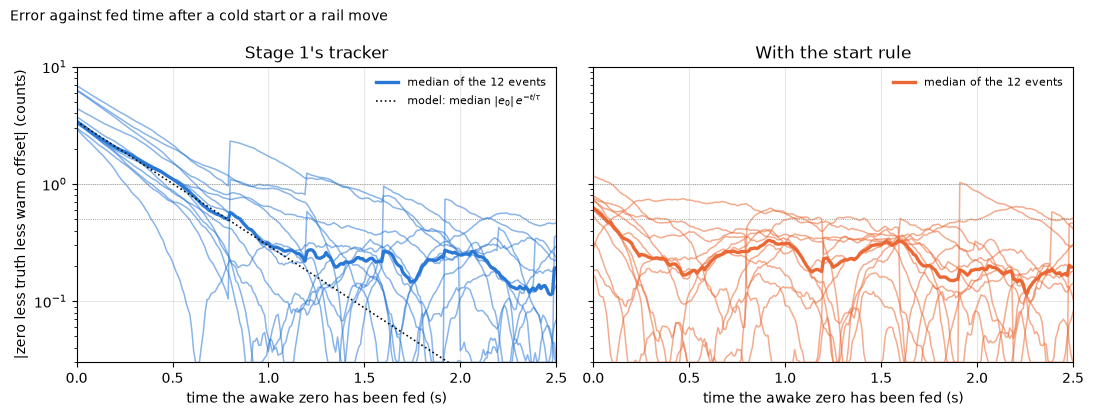

In [41]:
big = BIG["sweep"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
panels = ((axes[0], CUR, BLUE, "Stage 1's tracker"),
          (axes[1], CUR2, ORANGE, "With the start rule"))
for ax, cur, color, title in panels:
    cur = cur[cur["sweep"].isin(big)]
    for _, g in cur.groupby("sweep"):
        ax.plot(g["fed_s"], g["err"].abs().clip(lower=0.03), color=color,
                lw=1.1, alpha=0.55)
    med = cur.groupby(cur["fed_s"].round(2))["err"].apply(
        lambda x: x.abs().median())
    ax.plot(med.index, med.clip(lower=0.03), color=color, lw=2.4,
            label=f"median of the {len(big)} events")
    for thr in (1.0, 0.5):
        ax.axhline(thr, **figures.EDGE_STYLE)
    ax.set_yscale("log")
    ax.set_ylim(0.03, 10)
    ax.set_xlim(0, 2.5)
    figures.label(ax, x="time the awake zero has been fed (s)", title=title)
tt = np.linspace(0, 2.5, 100)           # s of feed
e_med = float(BIG["e0"].abs().median())
axes[0].plot(tt, e_med * np.exp(-tt / TAU_S), color=INK, lw=1.2, ls=":",
             label=r"model: median $|e_0|\,e^{-t/\tau}$")
axes[0].set_ylabel("|zero less truth less warm offset| (counts)")
for ax in axes:
    ax.legend(frameon=False, loc="upper right", fontsize=8)
fig.suptitle("Error against fed time after a cold start or a rail move",
             x=0.01, ha="left", fontsize=10)
figures.finish(fig)

What you are looking at: the central figure of the notebook. Each thin line is one of the 12 events with a start error over 1.5 counts, its absolute error against the time the awake zero has been fed since its first drive, on a log scale, the thick line their median. The dotted lines mark one and half a count. Left, stage 1's tracker, with the model $|e_0|\,e^{-t/\tau}$ at the median start error. Right, the same events under the start rule, read 5 ms into the first drive. Under stage 1's tracker the errors start at 3 to 7 counts and fall along the model until they reach the warm scatter near 0.3 counts, about 1 s of feed later. Under the start rule they open inside 1.2 counts and sit in the warm scatter from the first fed tick. On the 12 events the start error falls from a median of 3.41 counts to 0.62, worst 6.91 to 1.17, and the fed time to within half a count from 0.78 s to 0.06 s, worst 0.30 s. Over all 18 events the start under the rule reads 0.59 counts rms.

## 5. The hold bound

A held zero is wrong by however far the true zero moves while nothing feeds it. The truth exists only in coasts, so its movement is read as a structure function, the difference of two truth readings against the time between them. All readings are 100 ms means of the crest column, from three sources.

- Inside one coast, every pair of whole 100 ms windows of a coast with its first 100 ms left out, lags of 0.1 to 2.9 s.
- Tail pairs inside a sweep, lags of 3 to 30 s. A sweep holds one tail per direction, so every such pair has a drive of the other direction between.
- Tail pairs across sweeps on one rail, 30 s to 2 h. One rail is within a tenth of a count of step on the line.

In [42]:
TAIL = int(round(sweeps.TAIL_S * FS))   # rows in a truth reading, 100 ms
RAW = STORE.arrays["raw"]
RAIL_SAME_V = 0.1 / SLOPE               # V worth 0.1 count of step


def tails():
    """Every coast tail, with the drive before it and its two halves."""
    t = RUNS[(RUNS["kind"] == sweeps.COAST) & RUNS["tail_raw"].notna()]
    t, d = t.copy(), RUNS[RUNS["kind"] == sweeps.DRIVE]
    j = np.searchsorted(d["i1"].to_numpy(), t["i0"].to_numpy(),
                        side="right") - 1
    prev = d.iloc[np.maximum(j, 0)]
    ok = (j >= 0) & (prev["sweep"].to_numpy() == t["sweep"].to_numpy())
    for k, col in (("rail_prev", "vbus"), ("duty_prev", "duty"),
                   ("raw_prev", "raw_s")):
        t[k] = np.where(ok, prev[col].to_numpy(), np.nan)
    t["duty_prev"] /= STORE.pwm_arr
    t["i_prev"] = t["raw_prev"] - t["tail_raw"]   # the drive's current
    for col in ("day", "experiment", "base_raw", "rail"):
        t[col] = SW[col].to_numpy()[t["sweep"].to_numpy()]
    t["rail_prev"] = t["rail_prev"].fillna(t["rail"])
    t["step"] = t["tail_raw"] - t["base_raw"]
    t["half_a"] = [RAW[i - TAIL:i - TAIL // 2].mean() for i in t["i1"]]
    t["half_b"] = [RAW[i - TAIL // 2:i].mean() for i in t["i1"]]
    t["coast_s"] = t["n"] / FS
    return t.reset_index(drop=True)


TAILS = tails()
print(f"{len(TAILS)} tails in {TAILS['sweep'].nunique()} sweeps; one rail "
      f"= within {RAIL_SAME_V:.3f} V")

446 tails in 244 sweeps; one rail = within 0.060 V


In [43]:
def pairs(t, col="tail_raw", max_lag=7200.0):
    """Every later-earlier pair of readings in col, with their lag in s."""
    i, j = np.triu_indices(len(t), 1)
    lag = t["t1"].to_numpy()[j] - t["t1"].to_numpy()[i]
    m = (lag > 0) & (lag <= max_lag)
    i, j, lag = i[m], j[m], lag[m]
    x, rp_ = t[col].to_numpy(), t["rail_prev"].to_numpy()
    p = pd.DataFrame(dict(lag=lag, d=x[j] - x[i], d_rail=rp_[j] - rp_[i],
                          sweep=t["sweep"].to_numpy()[i],
                          sweep_j=t["sweep"].to_numpy()[j]))
    p["same_sweep"] = p["sweep"] == p["sweep_j"]
    return p


def sf(p, bins):
    """The structure function: |difference| by lag bin."""
    rec = []
    for lo, hi in zip(bins[:-1], bins[1:]):
        g = p[(p["lag"] >= lo) & (p["lag"] < hi)]
        if len(g):
            a = g["d"].abs()
            rec.append(dict(lag_lo=lo, lag_hi=hi, pairs=len(g),
                            sweeps=g["sweep"].nunique(), mean=g["d"].mean(),
                            median=a.median(), p90=a.quantile(0.9),
                            worst=g["d"].iloc[int(a.to_numpy().argmax())]))
    return pd.DataFrame(rec)


def boot_q(g, q, n=1000, seed=1):
    """95 % bracket of a quantile of |d|, resampling the earlier sweep."""
    grp = [x.abs().to_numpy() for _, x in g.groupby("sweep")["d"]]
    if len(grp) < 4:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    out = [np.quantile(np.concatenate([grp[k] for k in rng.integers(
        0, len(grp), len(grp))]), q) for _ in range(n)]
    return tuple(np.percentile(out, [2.5, 97.5]))

In [44]:
h = TAILS["half_b"] - TAILS["half_a"]   # two halves of one tail, 50 ms
FLOOR = dict(lag_lo=0.05, lag_hi=0.05, pairs=len(h),
             sweeps=TAILS["sweep"].nunique(), mean=h.mean(),
             median=h.abs().median(), p90=h.abs().quantile(0.9),
             worst=h.iloc[int(h.abs().to_numpy().argmax())])
ALLP = pairs(TAILS)
SAME = ALLP[ALLP["d_rail"].abs() <= RAIL_SAME_V]   # one rail
rec, prof = [], []
for r in TAILS.itertuples():            # 100 ms windows inside each coast
    k = (r.n - TAIL) // TAIL            # whole windows past the first one
    if k < 2:
        continue
    m = RAW[r.i1 - k * TAIL:r.i1].reshape(k, TAIL).mean(1)
    ts = (r.n - (k - np.arange(k)) * TAIL) / FS     # s into the coast
    i, j = np.triu_indices(k, 1)
    rec.append(pd.DataFrame(dict(lag=(j - i) * TAIL / FS, d=m[j] - m[i],
                                 sweep=r.sweep, same_sweep=True)))
    prof.append(pd.DataFrame(dict(t=ts, d=m - m[-1], sweep=r.sweep,
                                  i_prev=r.i_prev, n=r.n)))
COASTP, PROF = pd.concat(rec), pd.concat(prof)
STRUCT = pd.concat([
    pd.DataFrame([FLOOR]).assign(source="two halves of one tail"),
    sf(COASTP, [0.05, 0.15, 0.3, 0.5, 1, 2, 3]).assign(source="in a coast"),
    sf(SAME, [3, 10, 30, 100, 300, 1000, 3600, 7200]).assign(
        source="tail pairs")])
print(STRUCT[["source", "lag_lo", "lag_hi", "pairs", "sweeps", "median",
              "p90", "worst", "mean"]].round(2).to_string(index=False))

                source  lag_lo  lag_hi  pairs  sweeps  median  p90  worst  mean
two halves of one tail    0.05    0.05    446     244    0.19 0.44  -1.03  0.00
            in a coast    0.05    0.15   2293     225    0.16 0.39  -0.89 -0.00
            in a coast    0.15    0.30   1887     102    0.19 0.49  -1.10 -0.01
            in a coast    0.30    0.50   3430      58    0.22 0.54  -1.39 -0.01
            in a coast    0.50    1.00   7360      55    0.23 0.57   1.45 -0.01
            in a coast    1.00    2.00   9545      55    0.24 0.60  -1.38 -0.01
            in a coast    2.00    3.00   2691      55    0.25 0.64  -1.31 -0.03
            tail pairs    3.00   10.00     23      17    0.31 0.47  -0.86 -0.12
            tail pairs   10.00   30.00    163     151    0.40 0.85   1.87  0.04
            tail pairs   30.00  100.00    602     196    0.39 0.94  -1.87 -0.01
            tail pairs  100.00  300.00   1364     190    0.40 0.98   1.99 -0.04
            tail pairs  300.00 1000.00  

Counts, the median and 90 % point of the absolute difference and the worst signed one. Two halves of one tail already differ by 0.19 median and 0.44 at the 90 % point, the floor of any pair of readings. Inside one coast the difference grows from 0.16 at 0.1 s to 0.25 at 2 to 3 s. The pairs inside a coast at 0.5 s and more come from 55 sweeps, 54 load sweeps and one pot-table sweep, all on 11-09 at 4.9 V. Between tails the median sits at 0.38 to 0.44 from 10 s to 1000 s, a flat band, and then climbs to 0.54 at 1 to 2 h with a mean drift of +0.25 to +0.53.

In [45]:
HORIZ = {1: (0.5, 2), 10: (3, 30), 60: (30, 120)}   # s: the lags used
rec = []
for hz, (lo, hi) in HORIZ.items():
    src = COASTP if hz == 1 else SAME
    g = src[(src["lag"] >= lo) & (src["lag"] < hi)]
    a = g["d"].abs()
    blo, bhi = boot_q(g, 0.9)
    rec.append(dict(horizon_s=hz, lags=f"{lo} to {hi} s", pairs=len(g),
                    sweeps=g["sweep"].nunique(),
                    days=len(set(SW["day"].to_numpy()[g["sweep"]])),
                    median=a.median(), p90=a.quantile(0.9), p90_lo=blo,
                    p90_hi=bhi, p99=a.quantile(0.99),
                    worst=float(a.max()), rms=np.sqrt((g["d"] ** 2).mean())))
HORIZONS = pd.DataFrame(rec).set_index("horizon_s")
print(HORIZONS.round(2).to_string())
g60 = SAME[(SAME["lag"] >= 30) & (SAME["lag"] < 120)]
for by, key in (("day", SW["day"]), ("rail", SW["band"])):
    k = key.to_numpy()[g60["sweep"]]
    print(f"60 s by {by} (median, 90 %, pairs):",
          {str(v): (float(round(x.abs().median(), 2)),
                    float(round(x.abs().quantile(0.9), 2)), len(x))
           for v, x in g60["d"].groupby(k)})

                  lags  pairs  sweeps  days  median   p90  p90_lo  p90_hi   p99  worst   rms
horizon_s                                                                                   
1           0.5 to 2 s  16905      55     1    0.24  0.59    0.55    0.62  0.94   1.45  0.36
10           3 to 30 s    186     162     4    0.38  0.81    0.74    0.96  1.54   1.87  0.54
60         30 to 120 s    759     198     4    0.38  0.95    0.88    0.99  1.53   1.87  0.56
60 s by day (median, 90 %, pairs): {'11-06': (0.36, 0.93, 502), '11-07': (0.49, 1.02, 45), '11-08': (0.38, 0.97, 47), '11-09': (0.39, 0.93, 165)}
60 s by rail (median, 90 %, pairs): {'3.6': (0.39, 0.97, 153), '4.9': (0.37, 0.92, 435), '6.0-6.8': (0.4, 1.37, 20), '7.0-7.6': (0.37, 0.97, 151)}


On a steady rail a held awake zero is good to under a count at the 90 % point at every horizon asked, 0.59 counts after 1 s, 0.81 after 10 s and 0.95 after 60 s, worst 1.45, 1.87 and 1.87. These include the noise of the two 100 ms readings themselves, so they are upper bounds on the zero's own movement. Confidence is high at 10 and 60 s, 162 and 198 sweeps over four days and three rail sets, and moderate at 1 s, 55 sweeps of one day at one rail and inside a coast, where nothing drives. At 60 s the days read 0.93 to 1.02 at the 90 % point and the rails 0.92 to 0.97, except the sag's 6.0-6.8 V band, 1.37 over 20 pairs.

### What moves it

The step over the asleep zero, the asleep baseline and the sweep's mean truth are paired across sweeps on one rail the same way, from 30 s to 2 h. Then the rail itself, across sweep pairs at any rail.

In [46]:
s1 = SW[SW["base_raw"].notna()].reset_index(names="sweep")
s1 = s1.assign(t1=s1["t_start"], rail_prev=s1["rail"])
pb = pairs(s1, "base_raw")
pb = pb[pb["d_rail"].abs().fillna(0) <= RAIL_SAME_V]
s2 = s1[s1["truth"].notna()].reset_index(drop=True)
s2["step"] = s2["truth"] - s2["base_raw"]
LONG = [30, 100, 300, 1000, 3600, 7200]   # s, the lag bins across sweeps
rec = []
for what, p in (("asleep baseline", pb), ("step", pairs(s2, "step")),
                ("awake truth", pairs(s2, "truth"))):
    if what != "asleep baseline":
        p = p[p["d_rail"].abs() <= RAIL_SAME_V]
    rec.append(sf(p, LONG).assign(what=what))
HOURS = pd.concat(rec)
print(HOURS[["what", "lag_lo", "lag_hi", "pairs", "median", "p90", "worst",
             "mean"]].round(2).to_string(index=False))
anyp = pairs(s2, "truth").dropna(subset=["d_rail"])
RAIL_K = np.polyfit(anyp["d_rail"], anyp["d"], 1)[0]   # counts per V
big_move = anyp["d_rail"].abs() > 1
print(f"sweep pairs at any rail (n {len(anyp)}): {RAIL_K:.2f} counts per V "
      f"of rail move; median |d| {anyp['d'][big_move].abs().median():.2f} "
      f"for a move over 1 V (n {big_move.sum()}), "
      f"{anyp['d'][anyp['d_rail'].abs() <= RAIL_SAME_V].abs().median():.2f}"
      " on one rail")

           what  lag_lo  lag_hi  pairs  median  p90  worst  mean
asleep baseline      30     100    537    0.32 0.73  13.54  0.03
asleep baseline     100     300   1186    0.35 0.86  14.77  0.08
asleep baseline     300    1000   2980    0.38 0.96  14.57 -0.01
asleep baseline    1000    3600   6196    0.51 1.16  15.79  0.08
asleep baseline    3600    7200   6405    0.52 1.23   2.46  0.37
           step      30     100    229    0.34 0.80  -1.38 -0.01
           step     100     300    387    0.31 0.75   1.53 -0.02
           step     300    1000    560    0.32 0.79   1.60  0.00
           step    1000    3600    861    0.32 0.84   1.62 -0.03
           step    3600    7200   1095    0.33 0.86   1.51  0.06
    awake truth      30     100    229    0.31 0.79  -1.71 -0.01
    awake truth     100     300    387    0.31 0.81  -1.59 -0.04
    awake truth     300    1000    560    0.36 0.90  -1.60  0.04
    awake truth    1000    3600    861    0.46 1.28   2.44  0.16
    awake truth    3600  

Past 1000 s the awake truth drifts, a mean of +0.25 at 0.3 to 1 h and +0.53 at 1 to 2 h over the tail pairs above, +0.16 and +0.46 over the sweep means, and the asleep baseline drifts with it, +0.08 and +0.37. The step, the truth less its own sweep's baseline, does not. It stays at 0.31 to 0.34 median and 0.75 to 0.86 at the 90 % point from 30 s to 2 h. The stale rule makes a stale awake zero take the asleep zero's moves, so it removes that drift, and with section 4's five cold starts the held step is good for hours. Confidence is high. The asleep baseline's worst of 13.54 to 15.79 counts is one episode, at the end of this section.

The rail is what breaks a hold. Across sweep pairs at any rail the truth moves 1.88 counts per volt of rail, and a move over 1 V shifts it by 4.15 counts median against 0.42 on one rail. A hold is good to a count only while the rail stays within about half a volt, section 4's seed threshold seen from the other side.

In [47]:
tt = TAILS.dropna(subset=["rail_prev", "i_prev", "duty_prev", "step"])
tt = tt.assign(i100=tt["i_prev"] / 100)  # per 100 counts of current


def movers(cols, n=500, seed=1):
    """The step of each tail on the rail's curve plus cols: their
    coefficients, sd from resampling sweeps, and the residual sd."""
    v = tt["rail_prev"].to_numpy()
    X = np.c_[np.ones(len(tt)), v, v ** 2, *[tt[k] for k in cols]]
    y = tt["step"].to_numpy()
    co = np.linalg.lstsq(X, y, rcond=None)[0]
    rng, sws = np.random.default_rng(seed), tt["sweep"].unique()
    idx = {k: np.flatnonzero(tt["sweep"].to_numpy() == k) for k in sws}
    bs = []
    for _ in range(n):
        ii = np.concatenate([idx[k] for k in rng.choice(sws, len(sws))])
        bs.append(np.linalg.lstsq(X[ii], y[ii], rcond=None)[0])
    se = np.std(bs, 0)
    return dict(terms=" + ".join(cols) or "rail curve only",
                resid_sd=float((y - X @ co).std()),
                **{k: co[3 + i] for i, k in enumerate(cols)},
                **{k + "_se": se[3 + i] for i, k in enumerate(cols)})


MOVERS = pd.DataFrame([movers(c) for c in ((), ("i100",), ("duty_prev",),
                                           ("i100", "duty_prev"))])
print(f"{len(tt)} tails in {tt['sweep'].nunique()} sweeps")
print(MOVERS.round(3).to_string(index=False))

431 tails in 243 sweeps
           terms  resid_sd   i100  i100_se  duty_prev  duty_prev_se
 rail curve only     0.495    NaN      NaN        NaN           NaN
            i100     0.491 -0.086    0.033        NaN           NaN
       duty_prev     0.487    NaN      NaN     -0.326         0.098
i100 + duty_prev     0.487 -0.029    0.036     -0.281         0.110


In [48]:
ins = SAME[SAME["same_sweep"]]          # a drive of the other way between
late = COASTP[COASTP["lag"] >= 1]       # inside one coast, 1 to 3 s
rms_ins, rms_late = (np.sqrt((x["d"] ** 2).mean()) for x in (ins, late))
print(f"tail pairs with a drive between: rms {rms_ins:.2f} (n {len(ins)}); "
      f"inside one coast at 1 to 3 s: rms {rms_late:.2f} (n {len(late)}); "
      f"the difference in quadrature "
      f"{np.sqrt(max(rms_ins ** 2 - rms_late ** 2, 0)):.2f}")
dirn = RUNS.set_index("i0")["dirn"]
g = (TAILS.assign(dirn=dirn.reindex(TAILS["i0"]).to_numpy())
     .groupby(["sweep", "dirn"])["tail_raw"].mean().unstack())
dd = (g[1] - g[-1]).dropna()            # forward less reverse, per sweep
print(f"tail after a forward drive less after a reverse: {dd.mean():+.3f} "
      f"se {dd.std() / np.sqrt(len(dd)):.3f}, {len(dd)} sweeps")
x = PROF[(PROF["t"] > 0.09) & (PROF["t"] <= 0.15)
         & (PROF["t"] < PROF["n"] / FS - 0.11)]["d"]
print(f"window at 0.1 to 0.15 s less the coast's last: {x.mean():+.2f} se "
      f"{x.std() / np.sqrt(len(x)):.2f}, n {len(x)}")
first = PROF[(PROF["t"] < 0.15) & (PROF["n"] / FS > 0.3)]
x = first[first["i_prev"] > 200]["d"]   # after a heavy drive
print(f"the same after a drive over 200 counts: {x.mean():+.2f} se "
      f"{x.std() / np.sqrt(len(x)):.2f}, n {len(x)}")

tail pairs with a drive between: rms 0.54 (n 187); inside one coast at 1 to 3 s: rms 0.37 (n 12236); the difference in quadrature 0.40
tail after a forward drive less after a reverse: -0.025 se 0.040, 188 sweeps
window at 0.1 to 0.15 s less the coast's last: +0.03 se 0.04, n 60
the same after a drive over 200 counts: +0.28 se 0.11, n 9


Beside the rail the movers are small. The duty of the drive before a tail moves its step by -0.326 counts per unit duty, sd 0.098 from resampling sweeps, about 3 sigma, and -0.2 counts after a 60 % drive. The residual falls only from 0.495 to 0.487. The drive's current alone reads -0.086 per 100 counts and beside the duty -0.029 $\pm$ 0.036, not a finding. A drive between two readings adds to their difference, rms 0.54 either side of a drive against 0.37 inside one coast at 1 to 3 s, +0.40 in quadrature. That is high-confidence real, and its cause is not separated. The direction of the drive moves nothing, -0.025 $\pm$ 0.040 over 188 sweeps. Inside a coast the window at 0.1 to 0.15 s sits +0.03 $\pm$ 0.04 above the last window. After a drive over 200 counts it sits +0.28 $\pm$ 0.11 above, 2.4 sigma on 9 coasts of one day, a candidate only. The rms of 0.37 is over 12236 pairs.

In [49]:
_, KIND1, _ = zr.replay(STAGE1_RULE, STORE)
unfed = (KIND1 == zr.K_NONE) & (BRIDGE != sweeps.ASLEEP)
brk = np.flatnonzero(np.diff(np.r_[0, unfed.astype(np.int8), 0]))
UNFED_S = (brk[1::2] - brk[::2]) / FS   # s, each unfed awake stretch
wide = DRIVE_ROWS & (STORE.arrays["duty"] > zr.gate_ticks(
    zr.GATE_REC_PCT, STORE.pwm_arr))
print(f"unfed awake stretches: {len(UNFED_S)}, median "
      f"{np.median(UNFED_S):.2f} s, 90 % {np.quantile(UNFED_S, .9):.2f} s, "
      f"longest {UNFED_S.max():.2f} s, over 1 s {(UNFED_S > 1).sum()}")
print(f"drive rows wider than the gate: "
      f"{100 * wide.sum() / DRIVE_ROWS.sum():.1f} % of drive rows")

unfed awake stretches: 1064, median 0.00 s, 90 % 0.24 s, longest 2.40 s, over 1 s 4
drive rows wider than the gate: 14.7 % of drive rows


What the data does not bound. The zero during a wide drive is not seen, because the truth exists only in a coast 100 ms or more after the drive ends, and anything that relaxes faster is invisible. A long unfed drive is not in the data. The longest stretch of awake rows with no feed is 2.40 s, 4 of 1064 stretches are over 1 s and 90 % are under 0.24 s, while 14.7 % of the drive rows are wider than the gate. The 10 and 60 s bounds are the truth either side of mixed histories, rungs, seeks and rests whose bridge state the rows do not show, not either side of a 10 or 60 s wide drive. A rail that sags under the drive is not separated (section 4), and temperature is not in the rows.

In [50]:
low = SW[SW["base_raw"] < SW["base_raw"].median() - 5]   # 5 counts under
rest = SW["base_raw"].drop(low.index)
EPISODE_SHIFT = SW["base_raw"].median() - low["base_raw"].mean()
print(f"the low baselines sit {EPISODE_SHIFT:.1f} counts under the median")
print(f"asleep baselines 5 counts or more under the median "
      f"{SW['base_raw'].median():.1f}: sweeps {low.index.tolist()}")
print(f"every other baseline: sd {rest.std():.2f}, {rest.min():.1f} to "
      f"{rest.max():.1f} counts (n {len(rest)})")
for s_ in range(low.index.min(), low.index.max() + 2):
    co = RUNS[(RUNS["sweep"] == s_) & (RUNS["kind"] == sweeps.COAST)]
    print(f"sweep {s_} {SW['folder'].iat[s_]}: rail {SW['rail'].iat[s_]:.2f}"
          f" V, rest before {SW['gap_s'].iat[s_]:.0f} s, baseline "
          f"{SW['base_raw'].iat[s_]:.1f}, coast crest "
          f"{(co['raw'] * co['n']).sum() / co['n'].sum():.1f}")
print("the six lowest rails of all sweeps:",
      np.sort(SW["rail"].dropna().to_numpy())[:6].round(2).tolist(), "V")
lap = pd.read_csv(PAIR_DIR / "resistance/locked-4/chains.csv")
print(lap[["k", "volts_set", "dps_read", "vsys_read"]].head(4)
      .to_string(index=False))

the low baselines sit 14.5 counts under the median
asleep baselines 5 counts or more under the median 1206.5: sweeps [193, 194, 195]
every other baseline: sd 0.60, 1204.9 to 1208.2 counts (n 518)
sweep 193 resistance/locked-4/chains/0: rail 3.46 V, rest before 139073 s, baseline 1191.2, coast crest 1195.9
sweep 194 resistance/locked-4/chains/1: rail 3.46 V, rest before 45 s, baseline 1192.4, coast crest 1196.2
sweep 195 resistance/locked-4/chains/2: rail 3.46 V, rest before 44 s, baseline 1192.5, coast crest 1194.0
sweep 196 resistance/locked-4/chains/3: rail 3.50 V, rest before 48 s, baseline 1206.0, coast crest 1209.0
the six lowest rails of all sweeps: [3.46, 3.46, 3.46, 3.5, 3.5, 3.5] V
 k  volts_set  dps_read  vsys_read
 0        3.3      3.55      3.289
 1        3.3      3.55      3.289
 2        3.3      3.55      3.289
 3        3.7      3.95      3.694


Three asleep baselines sit far under the rest. Sweeps 193 to 195, the first three of 11-07 in the resistance experiment's locked dataset, read 1191.2 to 1192.5 counts against a median of 1206.5, where the other 518 baselines hold an sd of 0.60 within 1204.9 to 1208.2. The coast rows of the same sweeps sit as low, 1194.0 to 1196.2 against 1209.0 in sweep 196, so both zeros moved together. These are the 3.3 V laps. The lap table gives the supply set to 3.3 V and the board's system rail read at 3.289 V, against 3.694 V on the 3.7 V laps that follow. Their rail at the terminal, 3.46 V, is the lowest of all 521 sweeps. The reading is that the system rail sits under what the board's regulator needs to hold its output, which moves the amplifier's reference and with it both zeros. The 3.7 V laps 48 s later read 1206.0. A tracker that feeds the asleep zero follows the shift, and a zero held from before would be about 14.5 counts off. A servo whose system rail drops under the regulator's headroom has to treat its zero as unknown.

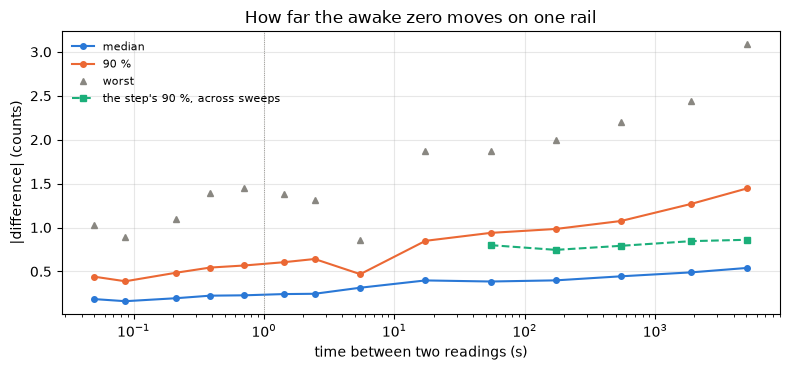

In [51]:
fig, ax = plt.subplots(figsize=(8, 3.8))
lag = np.sqrt(STRUCT["lag_lo"] * STRUCT["lag_hi"])   # s, bin's middle
for col, color, name in (("median", BLUE, "median"),
                         ("p90", ORANGE, "90 %")):
    ax.plot(lag, STRUCT[col], "o-", color=color, ms=4, label=name)
ax.plot(lag, STRUCT["worst"].abs(), "^", color=MUTED, ms=4, label="worst")
st = HOURS[HOURS["what"] == "step"]
ax.plot(np.sqrt(st["lag_lo"] * st["lag_hi"]), st["p90"], "s--",
        color=GREEN, ms=4, label="the step's 90 %, across sweeps")
ax.axvline(1.0, **figures.EDGE_STYLE)
ax.set_xscale("log")
figures.label(ax, x="time between two readings (s)",
              y="|difference| (counts)",
              title="How far the awake zero moves on one rail")
ax.legend(frameon=False, loc="upper left", fontsize=8)
figures.finish(fig)

What you are looking at: the structure function of the awake truth on one rail, the median, 90 % point and worst of the absolute difference of two 100 ms readings against the time between them, from the two halves of one tail at 0.05 s to tail pairs 2 h apart, and the 90 % point of the step over the asleep zero across sweeps. The awake zero's movement saturates near 0.4 counts median from 10 s on and climbs past 1000 s, where the step stays flat.

## 6. Noise against the time constant

### The sample, per tick

The noise of the trough sample is read on settled stretches only. The asleep baselines with their first 0.2 s dropped, the coasts with their first 100 ms dropped, and the drives at or under the gate, their settled second half. Each stretch gives its sd per tick, the sd from first differences, its Welch spectrum over short segments, its mean by tick mod 16, the phase of a 16-tick pattern the board puts on its channels, and its autocorrelation. The pot asleep runs through the same steps as a control, since its 16-tick pattern is known.

In [52]:
from scipy import signal

NSEG = 2048                             # rows per Welch segment
BASE_DROP = int(round(sweeps.BASE_DROP_S * FS))   # the baseline's head
GATE_TICKS = zr.gate_ticks(zr.GATE_REC_PCT, STORE.pwm_arr)


def segments():
    """(state, i0, i1, sweep) of every settled stretch."""
    out = []
    for s in range(len(SW)):
        a, n = int(SW["i0"].iat[s]), int(SW["base_n"].iat[s])
        if n >= BASE_DROP + NSEG:
            out.append(("asleep", a + BASE_DROP, a + n, s))
    co = RUNS[(RUNS["kind"] == sweeps.COAST) & (RUNS["n"] >= TAIL + NSEG)]
    out += [("coast", int(r.i0) + TAIL, int(r.i1), int(r.sweep))
            for r in co.itertuples()]
    dr = RUNS[(RUNS["kind"] == sweeps.DRIVE) & (RUNS["duty_min"] > 0)
              & (RUNS["duty_max"] <= GATE_TICKS) & (RUNS["n"] >= 2 * NSEG)]
    out += [("narrow drive", int(r.i0) + int(r.n) // 2, int(r.i1),
             int(r.sweep)) for r in dr.itertuples()]
    return pd.DataFrame(out, columns=["state", "i0", "i1", "sweep"])


SEG = segments()
print("stretches:", SEG["state"].value_counts().to_dict(), "| rows",
      {k: int((g["i1"] - g["i0"]).sum()) for k, g in SEG.groupby("state")})

stretches: {'asleep': 520, 'narrow drive': 461, 'coast': 446} | rows {'asleep': 3120000, 'coast': 6248116, 'narrow drive': 3345511}


In [53]:
LAGS = np.array([1, 2, 3, 4, 8, 16, 32, 64])   # ticks


def per_segment(seg, col):
    """Per stretch: sd, sd from differences; per state: mean spectrum,
    the folds by tick mod 16, the mean autocorrelation at LAGS."""
    x_all, ph_all = STORE.arrays[col], STORE.arrays["ph"]
    rec, psd, folds, acf = [], {}, {}, {}
    for r in seg.itertuples():
        x, ph = x_all[r.i0:r.i1].astype(float), ph_all[r.i0:r.i1]
        d = x - x.mean()
        f, p = signal.welch(d, fs=FS, nperseg=NSEG, detrend="linear")
        psd.setdefault(r.state, []).append(p)
        folds.setdefault(r.state, []).append(
            [d[ph == k].mean() if (ph == k).any() else np.nan
             for k in range(16)])
        v = d.var()
        acf.setdefault(r.state, []).append(
            [(d[:-k] * d[k:]).mean() / v if v > 0 else np.nan
             for k in LAGS])
        rec.append(dict(state=r.state, sweep=r.sweep, n=len(x), sd=x.std(),
                        sd_diff=np.diff(x).std() / np.sqrt(2)))
    return (pd.DataFrame(rec), f, {k: np.mean(v, 0) for k, v in psd.items()},
            {k: np.array(v) for k, v in folds.items()},
            {k: np.nanmean(v, 0) for k, v in acf.items()})


NOISE = {col: per_segment(SEG if col != "pos" else
                          SEG[SEG["state"] == "asleep"], col)
         for col in ("trough", "raw", "pos")}
print("per-stretch tables, spectra and folds for the trough, crest and pot")

per-stretch tables, spectra and folds for the trough, crest and pot


In [54]:
def line_ratio(f, p, f0):
    """The spectrum at f0 over the median of its neighbors."""
    j = int(round(f0 / (f[1] - f[0])))
    return p[j] / np.median(np.r_[p[j - 12:j - 2], p[j + 3:j + 13]])


rec = []
for col, (t, f, P, F, A) in NOISE.items():
    for st in P:
        g = t[t["state"] == st]
        fm = np.nanmean(F[st], 0)       # the mean pattern by tick mod 16
        days = SW["day"].to_numpy()[g["sweep"].to_numpy()]
        byday = [np.nanmean(F[st][days == d], 0) for d in np.unique(days)]
        cc = [np.corrcoef(a, b)[0, 1] for i, a in enumerate(byday)
              for b in byday[i + 1:]]
        sd = g["sd"].median()
        white = np.sqrt(np.median(P[st][f > 2000]) * FS / 2)
        rec.append(dict(column=col, state=st, n=len(g), sd=sd,
                        sd_10=g["sd"].quantile(.1), sd_90=g["sd"].quantile(.9),
                        sd_diff=g["sd_diff"].median(), white=white,
                        fold_pp=np.ptp(fm), fold_sd=fm.std(),
                        fold_share=fm.var() / sd ** 2,
                        r_days_min=min(cc) if cc else np.nan,
                        **{f"line_{int(k * FS / 16)}": line_ratio(
                            f, P[st], k * FS / 16) for k in (1, 2, 4)}))
TICK_NOISE = pd.DataFrame(rec)
print(TICK_NOISE.round(2).to_string(index=False))
print("trough autocorrelation at lags", LAGS.tolist(), "ticks:",
      {st: np.round(a, 2).tolist() for st, a in NOISE["trough"][4].items()})

column        state   n   sd  sd_10  sd_90  sd_diff  white  fold_pp  fold_sd  fold_share  r_days_min  line_1250  line_2500  line_5000
trough       asleep 520 1.06   1.02   1.11     0.93   0.89     1.04     0.30        0.08        0.95      18.41      58.31       3.95
trough        coast 446 1.11   1.04   1.46     0.99   1.01     1.00     0.30        0.07        0.94      11.80      53.96       7.34
trough narrow drive 461 1.16   1.04   1.44     1.03   1.02     0.97     0.27        0.05        0.88      10.12      40.19       6.55
   raw       asleep 520 1.02   0.99   1.06     0.89   0.87     1.06     0.31        0.09        0.98      16.44      63.68       6.56
   raw        coast 446 1.08   1.02   1.47     0.94   1.01     1.16     0.36        0.11        0.97      18.26      69.20       5.43
   raw narrow drive 461 9.30   1.07  18.30     1.79   2.59     1.21     0.36        0.00        0.95       1.29       4.00       1.76
   pos       asleep 520 1.03   0.92   1.34     0.70   0.55    

One tick of the trough carries 1.06 counts sd asleep, 1.11 in a coast and 1.16 under a narrow drive, over 520, 446 and 461 stretches and four days. The crest column with no current reads 1.02 asleep and 1.08 in a coast. Rows are not independent. A 16-tick pattern of about one count peak to peak, 1.04, 1.00 and 0.97 by state with an sd of 0.27 to 0.30, holds 5 to 8 % of the variance. It is the same on every day, the folded patterns correlating at 0.88 or more between days, and it is in both columns and every bridge state. The same steps find the pot's known pattern at 3.06 counts. Lines at 1250 and 2500 Hz, the 16-tick rate and its second harmonic, stand 10 to 58 times over their neighbors. A tracker fed on every tick averages the pattern to nothing. One fed on every 16th tick would take up to half a count of it as a constant. The autocorrelation stays at 0.10 to 0.23 out to 64 ticks.

In [55]:
t = NOISE["trough"][0].copy()
t["band"] = rail_band(SW["rail"].to_numpy()[t["sweep"]])
t["day"] = SW["day"].to_numpy()[t["sweep"]]
print("trough sd per tick, median by rail")
print(t.groupby(["state", "band"], observed=True)["sd"].median().round(2)
      .unstack(0).to_string())
print("by day")
print(t.groupby(["state", "day"])["sd"].median().round(2).unstack(0)
      .to_string())

trough sd per tick, median by rail
state    asleep  coast  narrow drive
band                                
3.6        1.06   1.04          1.09
4.9        1.06   1.10          1.12
6.0-6.8    1.03   1.45          1.44
7.0-7.6    1.04   1.45          1.42
>7.8       1.03   1.39          1.34
by day
state  asleep  coast  narrow drive
day                               
11-06    1.04   1.12          1.22
11-07    1.06   1.16          1.26
11-08    1.05   1.07          1.26
11-09    1.07   1.09          1.11


Asleep the sd is 1.03 to 1.06 at every rail. Awake it rises from about 1.1 at 3.6 and 4.9 V to about 1.4 from 6 V up, 1.34 to 1.45. By day it moves by 0.03 asleep, 0.09 in a coast and 0.15 under a narrow drive.

In [56]:
NL = 16384                              # rows per segment, 1.2 Hz bins
LOW_BANDS = ((0.5, 2), (2, 5), (5, 15), (15, 50), (50, 200))   # Hz
rec, LOW_P = [], {}
for st, col in (("coast", "trough"), ("coast", "raw"),
                ("coast", "raw less trough"), ("narrow drive", "trough")):
    sg = SEG[(SEG["state"] == st) & (SEG["i1"] - SEG["i0"] >= NL)]
    ps = []
    for r in sg.itertuples():
        x = (STORE.arrays["raw"][r.i0:r.i1].astype(float)
             - STORE.arrays["trough"][r.i0:r.i1] if col == "raw less trough"
             else STORE.arrays[col][r.i0:r.i1].astype(float))
        fl, pl = signal.welch(x - x.mean(), fs=FS, nperseg=NL,
                              detrend="constant")
        ps.append(pl)
    pl = np.mean(ps, 0)
    LOW_P[(st, col)] = (fl, pl)
    hf = np.median(pl[fl > 2000])       # the white floor, counts^2/Hz
    r = dict(state=st, column=col, stretches=len(ps),
             sweeps=sg["sweep"].nunique())
    for lo, hi in LOW_BANDS:
        m = (fl >= lo) & (fl < hi)
        r[f"{lo}-{hi} Hz"] = pl[m].mean() / hf
    rec.append(r)
LOW = pd.DataFrame(rec)
print(f"power over the white floor, resolution {fl[1] - fl[0]:.2f} Hz")
print(LOW.round(2).to_string(index=False))

power over the white floor, resolution 1.22 Hz
       state          column  stretches  sweeps  0.5-2 Hz  2-5 Hz  5-15 Hz  15-50 Hz  50-200 Hz
       coast          trough         69      55    162.05   74.77    27.56     11.95       4.25
       coast             raw         69      55    168.06   78.13    28.63     12.34       4.38
       coast raw less trough         69      55      1.10    1.08     0.97      0.97       0.98
narrow drive          trough          4       2     96.68   95.52    35.77     14.51       4.49


From the 69 coasts of 0.8 s and more, 55 sweeps of one day, the low end climbs as 1/f, 162 times the white floor at 0.5 to 2 Hz and about 4 times at 50 to 200 Hz. That low end is why two 100 ms means 0.1 s apart differ by 0.16 counts median in section 5, where white noise of 1.1 counts would give 0.03. It is common to the two columns. The crest less the trough is white down to the lowest band, 0.97 to 1.10 times its floor. The only 4 narrow-drive stretches long enough, in 2 sweeps, show the same shape.

The low end is the amplifier's own wander, or its reference's, and the trough sees all of it. A tracker that follows it takes it out of the reading. It is the zero moving, not noise on the zero. Confidence is high in a coast and low under a drive, with 4 stretches.

### The zero against alpha

Seven trackers are replayed over everything, $\alpha = 2^{-9}$ to $2^{-15}$, each with stage 1's rule and with the start rule. The zero's noise is read three ways. The white floor through the filter, $\sigma\sqrt{\alpha / (2 - \alpha)}$. The measured coast spectrum from 0.6 Hz up through the filter's response. And the zero's own sd over the last 2 s of the coasts of 2.5 s and more, as replayed. The reading's zero error in a coast is the 5 ms mean of the crest column less the zero at the same instant, its sd inside a coast. The time to close a start error to half a count is $\tau \ln(|e_0| / 0.5)$, for this servo's boot, its median rail move and the residual after the seed. The warm score is paired against $2^{-13}$ over the same runs. Section 7 adds the design with its constant to the same scan.

In [57]:
SHIFTS = (9, 10, 11, 12, 13, 14, 15)    # alpha = 2^-shift
WIN = int(round(0.005 * FS))            # rows in a 5 ms reading
COASTS = RUNS[(RUNS["kind"] == sweeps.COAST) & RUNS["tail_raw"].notna()]


def coast_metrics(out):
    """In the coasts with a tail, the last 2 s past the first 100 ms:
    the zero's own sd and the reading's zero error, 5 ms means."""
    jit, err_sd, err_all = [], [], []
    for r in COASTS.itertuples():
        k = min(int(r.n) - TAIL, 2 * FS) // WIN    # whole 5 ms windows
        a, e = int(r.i1) - k * WIN, int(r.i1)
        z = out[a:e].reshape(-1, WIN).mean(1)
        d = RAW[a:e].reshape(-1, WIN).mean(1) - z
        err_all.append(d)
        if r.n >= 2.5 * FS:
            jit.append(z.std())
            err_sd.append(d.std())
    return dict(z_sd_2s_coast=float(np.median(jit)), n_long=len(jit),
                read_sd_coast=float(np.median(err_sd)),
                n_win=len(np.concatenate(err_all)))


def from_spectrum(alpha, f, p):
    """sd of the tracker's output for a spectrum p (0.6 Hz up) and for
    its white floor alone."""
    H2 = alpha ** 2 / (1 + (1 - alpha) ** 2
                       - 2 * (1 - alpha) * np.cos(2 * np.pi * f / FS))
    hf = np.median(p[f > 2000])
    return (float(np.sqrt((p[1:] * H2[1:]).sum() * (f[1] - f[0]))),
            float(np.sqrt(hf * FS / 2 * alpha / (2 - alpha))))

In [58]:
def drive_end(out):
    """The zero on a drive's last row less the crest over the first 100 ms
    of the coast after it (settle ticks out), warm sweeps, by whether the
    drive fed: a truth 0.1 s away."""
    co = RUNS[(RUNS["kind"] == sweeps.COAST)
              & (RUNS["n"] >= TAIL + zr.ZERO_SETTLE_TICKS)]
    dr = RUNS[RUNS["kind"] == sweeps.DRIVE].set_index("i1")
    cls, st, rec = SW["cls"].to_numpy(), zr.ZERO_SETTLE_TICKS, []
    for r in co.itertuples():
        if r.i0 in dr.index and cls[r.sweep] == "warm":
            truth = RAW[r.i0 + st:r.i0 + st + TAIL].mean()
            rec.append((out[r.i0 - 1] - truth,
                        dr.loc[r.i0, "duty_max"] <= GATE_TICKS))
    e = pd.DataFrame(rec, columns=["e", "fed"])
    return {f"end_{nm}_{k}": v for nm, g in (("fed", e[e["fed"]]),
                                             ("held", e[~e["fed"]]))
            for k, v in (("sd", g["e"].std()), ("n", len(g)))}


E_BOOT = float(EV.loc[EV["sweep"] == 0, "e0"].abs().iloc[0])
E_MOVE = float(EV.loc[EV["cls"] == "rail moved", "e0"].abs().median())
E_SEED = float(EV2.loc[EV["e0"].abs() > 1.5, "e0"].abs().median())
print(f"start errors closed: boot {E_BOOT:.2f}, rail move (median) "
      f"{E_MOVE:.2f}, after the seed (median) {E_SEED:.2f} counts")

start errors closed: boot 6.36, rail move (median) 3.37, after the seed (median) 0.62 counts


In [59]:
def scan_row(sh, keep):
    """One alpha: noise, closing times and the warm scores."""
    a, tau = 2.0 ** -sh, 2.0 ** sh / FS
    row = dict(shift=sh, tau_s=tau, corner_hz=1 / (2 * np.pi * tau))
    for pre, rule in (("", zr.Rule(shift=sh)),
                      ("seed_", seeded("set", 1, **START, shift=sh))):
        d, out, _ = zr.score(rule, STORE, keep=True)
        d = zr.classes(d, SW, HALF_COUNT_V, LONG_GAP_S)
        w, ev = d[d["cls"] == "warm"], d[d["cls"] != "warm"]
        keep[(pre, sh)] = w
        lo, hi = zr.boot_rms(w, "err_mean")
        st, se = zr.stats(w["err_mean"]), zr.stats(ev["err_mean"])
        row.update({pre + "warm_rms": st["rms"], pre + "warm_lo": lo,
                    pre + "warm_hi": hi, pre + "warm_mean": st["mean"],
                    pre + "warm_sd": st["sd"], pre + "ev_rms": se["rms"]})
        if not pre:
            row.update(coast_metrics(out))
            row.update(drive_end(out))
    f, p = LOW_P[("coast", "trough")]
    row["z_sd_spectrum"], row["z_sd_white"] = from_spectrum(a, f, p)
    for nm, e0 in (("boot", E_BOOT), ("move", E_MOVE), ("seeded", E_SEED)):
        row[f"close_{nm}_s"] = tau * np.log(max(e0 / 0.5, 1.0))
    return row


KEEP_A = {}
ALPHA = pd.DataFrame([scan_row(sh, KEEP_A) for sh in SHIFTS])
for pre in ("", "seed_"):
    pd_ = [paired(KEEP_A[(pre, sh)], KEEP_A[(pre, zr.ALPHA_SHIFT)])
           for sh in SHIFTS]
    for i, k in enumerate(("d13", "d13_lo", "d13_hi")):
        ALPHA[pre + k] = [x[i] for x in pd_]
print("alpha scanned")

alpha scanned


In [60]:
show_cols = ["shift", "tau_s", "z_sd_white", "z_sd_spectrum",
             "z_sd_2s_coast", "read_sd_coast", "close_boot_s",
             "close_move_s", "close_seeded_s"]
print(ALPHA[show_cols].round(3).to_string(index=False))
print(ALPHA[["shift", "warm_rms", "warm_lo", "warm_hi", "warm_mean",
             "d13", "d13_lo", "d13_hi", "seed_warm_rms", "seed_warm_mean",
             "seed_d13", "seed_d13_lo", "seed_d13_hi"]].round(3)
      .to_string(index=False))
a0 = ALPHA.iloc[0]
print(f"coasts with a tail {len(COASTS)}, of 2.5 s or more "
      f"{int(a0['n_long'])}, 5 ms windows {int(a0['n_win'])}")

 shift  tau_s  z_sd_white  z_sd_spectrum  z_sd_2s_coast  read_sd_coast  close_boot_s  close_move_s  close_seeded_s
     9  0.026       0.028          0.205          0.237          0.272         0.065         0.049           0.006
    10  0.051       0.020          0.167          0.203          0.294         0.130         0.098           0.011
    11  0.102       0.014          0.124          0.170          0.316         0.260         0.195           0.023
    12  0.205       0.010          0.079          0.127          0.335         0.521         0.391           0.045
    13  0.410       0.007          0.044          0.090          0.345         1.042         0.781           0.090
    14  0.819       0.005          0.022          0.062          0.358         2.084         1.563           0.181
    15  1.638       0.004          0.011          0.042          0.363         4.167         3.125           0.361
 shift  warm_rms  warm_lo  warm_hi  warm_mean   d13  d13_lo  d13_hi  seed_warm_r

Noise does not set the time constant. The white part of the zero's noise is 0.004 to 0.028 counts over the whole range, 0.007 at $2^{-13}$, a hundredth of the warm scatter. What moves a fast zero is the amplifier's wander, 0.09 counts sd over a 2 s coast at $2^{-13}$ and 0.24 at $2^{-9}$. Following it helps the reading where it is checked at the same instant. The reading's zero error in a coast falls from 0.35 to 0.27 counts as alpha goes from $2^{-13}$ to $2^{-9}$.

Against the stage 3 truth, $2^{-13}$ is the minimum of stage 1's rule on this servo, in a flat band from $2^{-12}$ to $2^{-14}$. The neighbors cost +0.020 and +0.021 counts. Faster than $2^{-12}$ costs 0.05 to 0.11 counts and $2^{-15}$ costs 0.10, clear of zero. Under stage 1's rule the mean climbs from +0.58 at $2^{-13}$ to +0.67 at $2^{-9}$, because a fast zero settles on the trough of the drive it is in, which sits above the coast's (section 3). With the start rule and no constant, slower scores better, -0.024 at $2^{-14}$ and -0.030 at $2^{-15}$, all of it in the mean, +0.59 down to +0.54, a slow zero holding less of the drive feed's constant. Section 7 shows that this goes once the constant is out.

The cost of the time constant is the start. At $2^{-13}$ a boot takes 1.04 s of feed to reach half a count and a median rail move 0.78 s. After the seed the residual closes in 0.09 s, so with the seed in place a faster alpha buys nothing.

## 7. The drive-feed constant

The design carries one constant, the drive feed's offset. Per sweep it is the trough of the sweep's narrow drives, 30 % or under over their settled half, less the sweep's coast truth. The coast is fed from the crest column, so no constant is needed there, and the drive feed has the offset taken off. The constant is fitted on three days and scored on the warm runs of the fourth, paired against stage 1's tracker over the same runs. Its form as a line in the rail, its fit by capture set, and the form the servo measures itself, a running mean over its past sweeps only, are scored beside it.

In [61]:
def offsets():
    """Per sweep: its narrow drives' trough less its coast truth."""
    d = RUNS[(RUNS["kind"] == sweeps.DRIVE) & RUNS["truth"].notna()
             & (RUNS["duty"] <= GATE_TICKS) & (RUNS["duty"] > 0)]
    g = (d.assign(e=d["trough_s"] - d["truth"]).groupby("sweep")
         .agg(e=("e", "mean"), rail=("vbus", "mean")).reset_index())
    g["day"] = SW["day"].to_numpy()[g["sweep"]]
    g["set"] = (SW["experiment"] + "/" + SW["ds"]).to_numpy()[g["sweep"]]
    return g


OFF = offsets()
V_C = float(OFF["rail"].mean())         # V, the rail the line is about
print(f"{len(OFF)} sweeps: offset mean {OFF['e'].mean():.3f}, sd "
      f"{OFF['e'].std():.3f} between sweeps, se "
      f"{OFF['e'].std() / np.sqrt(len(OFF)):.3f}; mean rail {V_C:.2f} V")
for by, key in (("day", OFF["day"]), ("rail", rail_band(OFF["rail"]))):
    print(f"by {by} (mean, sd, n):",
          {str(k): (float(round(g.mean(), 3)), float(round(g.std(), 2)),
                    len(g))
           for k, g in OFF["e"].groupby(key, observed=True)})
b, a = np.polyfit(OFF["rail"] - V_C, OFF["e"], 1)
res = OFF["e"] - (a + b * (OFF["rail"] - V_C))
se_b = res.std(ddof=2) / (np.sqrt(len(OFF)) * (OFF["rail"] - V_C).std())
OFF_LINE = (a, b, se_b)
print(f"line in the rail, in sample: {a:.3f} + {b:.3f}({se_b:.3f}) x "
      f"(V - {V_C:.2f}), residual sd {res.std(ddof=2):.3f}, "
      f"{b / se_b:.1f} sigma")

186 sweeps: offset mean 0.667, sd 0.571 between sweeps, se 0.042; mean rail 5.33 V
by day (mean, sd, n): {'11-06': (0.646, 0.52, 111), '11-07': (0.812, 0.6, 7), '11-08': (0.674, 0.46, 8), '11-09': (0.688, 0.67, 60)}
by rail (mean, sd, n): {'3.6': (0.569, 0.49, 27), '4.9': (0.597, 0.59, 109), '6.0-6.8': (0.821, 0.64, 10), '7.0-7.6': (0.866, 0.51, 35), '>7.8': (1.014, 0.55, 5)}
line in the rail, in sample: 0.667 + 0.093(0.033) x (V - 5.33), residual sd 0.560, 2.8 sigma


The offset is 0.667 counts over 186 sweeps, sd 0.571 between sweeps, se 0.042. By day it reads 0.646 to 0.812. It rises with the rail, 0.569 at 3.6 V to 1.014 over 7.8 V, a slope of 0.093 $\pm$ 0.033 counts/V about 5.33 V, 2.8 sigma, and the line's residual sd of 0.560 is barely under the constant's 0.571. Section 3's in-sample offset, 0.67, is the same quantity rounded.

In [62]:
def held_out(by, line=False):
    """(offset, slope) per sweep from the other groups' sweeps. by None:
    in sample; 'past': the running mean of the sweeps before."""
    off, slope, rec = np.zeros(len(SW)), np.zeros(len(SW)), []

    def fit(t):
        if line and t["rail"].nunique() > 1:
            b_, a_ = np.polyfit(t["rail"] - V_C, t["e"], 1)
            return a_, b_
        return float(t["e"].mean()), 0.0
    if by is None:
        off[:], slope[:] = fit(OFF)
        return off, slope, pd.DataFrame()
    if by == "past":
        cs, cn = np.cumsum(OFF["e"].to_numpy()), np.arange(1, len(OFF) + 1)
        k = np.searchsorted(OFF["sweep"].to_numpy(), np.arange(len(SW))) - 1
        off = np.where(k >= 0, cs[np.maximum(k, 0)] / cn[np.maximum(k, 0)],
                       0.0)             # zero until a sweep has measured it
        return off, slope, pd.DataFrame()
    grp = (SW["day"] if by == "day"
           else SW["experiment"] + "/" + SW["ds"]).to_numpy()
    for g in pd.unique(grp):
        t, o = OFF[OFF[by] != g], OFF[OFF[by] == g]
        a_, b_ = fit(t)
        off[grp == g], slope[grp == g] = a_, b_
        if len(o):
            r = o["e"] - (a_ + b_ * (o["rail"] - V_C))
            rec.append(dict(fold=f"without {g}", n_fit=len(t), off=a_,
                            slope=b_, n_out=len(o), out_res=r.mean()))
    return off, slope, pd.DataFrame(rec)


def with_offset(by, line=False, **kw):
    """The float rule with the crest-fed coast and the held-out offset."""
    off, slope, _ = held_out(by, line)
    return zr.Rule(coast_raw=True, drive_off=off, drive_off_v=slope, v_c=V_C,
                   **kw)

In [63]:
FOLDS_DAY = held_out("day")[2]
print(FOLDS_DAY.round(3).to_string(index=False))
print("the line's folds by day:")
print(held_out("day", True)[2][["fold", "n_fit", "off", "slope",
                                 "out_res"]].round(2).to_string(index=False))

         fold  n_fit   off  slope  n_out  out_res
without 11-06     75 0.698    0.0    111   -0.052
without 11-07    179 0.661    0.0      7    0.151
without 11-08    178 0.667    0.0      8    0.007
without 11-09    126 0.657    0.0     60    0.031
the line's folds by day:
         fold  n_fit   off  slope  out_res
without 11-06     75 -0.54  -2.85     2.03
without 11-07    179  0.66   0.10     0.19
without 11-08    178  0.67   0.09     0.05
without 11-09    126  0.64   0.10     0.10


In [64]:
CONST_RULES = {
    "stage 1": STAGE1_RULE,
    "coast from the crest column, no offset": zr.Rule(coast_raw=True),
    "constant, in sample": with_offset(None),
    "constant, held out by day": with_offset("day"),
    "constant, held out by set": with_offset("set"),
    "constant from past sweeps only": with_offset("past"),
    "line in the rail, in sample": with_offset(None, True),
    "line in the rail, held out by set": with_offset("set", True),
    "line in the rail, held out by day": with_offset("day", True)}
rec, DC = [], {}
for name, rule in CONST_RULES.items():
    d = zr.classes(zr.score(rule, STORE), SW, HALF_COUNT_V, LONG_GAP_S)
    DC[name] = w = d[d["cls"] == "warm"]
    st, (lo, hi) = zr.stats(w["err_mean"]), zr.boot_rms(w, "err_mean")
    row = dict(rule=name, rms=st["rms"], lo=lo, hi=hi, mean=st["mean"],
               sd=st["sd"])
    band = rail_band(w["vbus"])
    row.update({f"mean {k}": g.mean() for k, g in
                w["err_mean"].groupby(band, observed=True)})
    rec.append(row)
CONST_T = pd.DataFrame(rec)
print(f"warm runs: {DC['stage 1']['err_mean'].notna().sum()}")
print(CONST_T.round(2).to_string(index=False))

warm runs: 911
                                  rule  rms   lo   hi  mean   sd  mean 3.6  mean 4.9  mean 6.0-6.8  mean 7.0-7.6  mean >7.8
                               stage 1 0.73 0.68 0.78  0.58 0.44      0.54      0.53          0.67          0.72       0.76
coast from the crest column, no offset 0.66 0.61 0.71  0.45 0.49      0.40      0.40          0.56          0.57       0.61
                   constant, in sample 0.42 0.37 0.47  0.05 0.41      0.03     -0.00          0.07          0.15       0.19
             constant, held out by day 0.41 0.37 0.46  0.03 0.41      0.01     -0.01          0.05          0.13       0.17
             constant, held out by set 0.42 0.37 0.47  0.04 0.42      0.01     -0.01          0.10          0.15       0.21
        constant from past sweeps only 0.43 0.39 0.48  0.09 0.42      0.11      0.03          0.09          0.21       0.24
           line in the rail, in sample 0.41 0.36 0.46  0.04 0.41      0.12      0.02          0.00          0.04     

The constant cross-validates. Fitted on any three days it is 0.657 to 0.698, and on the held-out day it takes the warm rms from 0.58 to 0.76 down to 0.32 to 0.44, with each fold's paired gain clear of zero. Pooled the held-out constant reads 0.41, bracket 0.37 to 0.46, the same as in sample to 0.002 counts. The integer port's in-sample 0.68 to 0.42 of section 3 holds in float and held out. What is left is scatter, a mean of +0.03 and an sd of 0.41 against the truth's own floor of section 5. The constant removes the bias, not the scatter, which moves from 0.44 to 0.41.

A line in the rail is not worth carrying. It flattens the warm mean by rail, +0.13 to +0.03 at 7.0-7.6 V, but moves the score by 0.011 counts. It is not held out by day at all. Only 11-06 has a truth off 4.9 V, the fold without it fits a slope of -2.85 on one rail, and on 11-06 it fails by 2 to 6 counts, 2.84 rms. Confidence is high that the line's gain is under 0.02 counts here and moderate on the slope itself.

The servo can measure the constant itself. A running mean over its past sweeps only, each sweep corrected with what the sweeps before it measured and starting from zero, scores 0.43, bracket 0.39 to 0.48, 0.015 counts behind the in-sample constant.

In [65]:
base, hd = DC["stage 1"], DC["constant, held out by day"]
for name, x, y in (
        ("held out by day less stage 1", hd, base),
        ("held out by day less in sample", hd, DC["constant, in sample"]),
        ("crest-fed coast alone less stage 1",
         DC["coast from the crest column, no offset"], base),
        ("line less constant, both by set",
         DC["line in the rail, held out by set"],
         DC["constant, held out by set"]),
        ("past sweeps less in sample", DC["constant from past sweeps only"],
         DC["constant, in sample"])):
    print(f"{name}: {paired(x, y)[0]:+.3f} [{paired(x, y)[1]:+.3f}, "
          f"{paired(x, y)[2]:+.3f}]")
OFF_DAY = held_out("day")[0]            # per sweep, held out by day
rec = []
for day in sorted(SW["day"].unique()):
    a_, b_ = hd[hd["day"] == day], base[base["day"] == day]
    v, lo, hi = paired(a_, b_)
    rec.append(dict(day=day, constant=OFF_DAY[(SW["day"] == day)][0],
                    rms=zr.stats(a_["err_mean"])["rms"],
                    stage1=zr.stats(b_["err_mean"])["rms"], paired=v,
                    lo=lo, hi=hi, n=int(a_["err_mean"].notna().sum())))
CONST_FOLDS = pd.DataFrame(rec)
print(CONST_FOLDS.round(3).to_string(index=False))

held out by day less stage 1: -0.316 [-0.356, -0.273]
held out by day less in sample: -0.002 [-0.004, -0.000]
crest-fed coast alone less stage 1: -0.069 [-0.083, -0.054]
line less constant, both by set: -0.011 [-0.020, -0.001]
past sweeps less in sample: +0.015 [+0.008, +0.022]
  day  constant   rms  stage1  paired     lo     hi   n
11-06     0.698 0.440   0.759  -0.319 -0.368 -0.264 633
11-07     0.661 0.393   0.671  -0.279 -0.381 -0.175  43
11-08     0.667 0.316   0.578  -0.263 -0.418 -0.068  43
11-09     0.657 0.347   0.674  -0.326 -0.392 -0.254 192


Each day's paired gain is -0.263 to -0.326 counts, every bracket clear of zero. Feeding the coast from the crest column alone, with no constant at all, gains 0.069 over stage 1. The design is a constant the servo measures itself, the mean over its narrow drives of the trough less the crest of the coast that follows, not a line and not a typed number. Leaving it in stays under a count, 0.73 rms, and is the form for a servo that has not yet seen a narrow drive followed by a coast.

### The time constant again, with the constant out

The scan of section 6, now with the full design, the start rule and the constant held out by day, and the zero on a drive's last row against the crest over the first 100 ms of the coast right after it, a truth 0.1 s away. Fed drives are at or under the gate, held drives wider.

In [66]:
full = []
for sh in SHIFTS:
    rule = seeded("set", 1, **START, shift=sh, coast_raw=True,
                  drive_off=OFF_DAY)
    d, out, _ = zr.score(rule, STORE, keep=True)
    d = zr.classes(d, SW, HALF_COUNT_V, LONG_GAP_S)
    KEEP_A[("full_", sh)] = w = d[d["cls"] == "warm"]
    st, (lo, hi) = zr.stats(w["err_mean"]), zr.boot_rms(w, "err_mean")
    full.append(dict(full_warm_rms=st["rms"], full_warm_lo=lo,
                     full_warm_hi=hi, full_warm_mean=st["mean"],
                     full_warm_sd=st["sd"],
                     **{"full_" + k: v for k, v in drive_end(out).items()}))
for k in full[0]:
    ALPHA[k] = [r[k] for r in full]
pd_ = [paired(KEEP_A[("full_", sh)], KEEP_A[("full_", zr.ALPHA_SHIFT)])
       for sh in SHIFTS]
for i, k in enumerate(("full_d13", "full_d13_lo", "full_d13_hi")):
    ALPHA[k] = [x[i] for x in pd_]
print(ALPHA[["shift", "full_warm_rms", "full_warm_lo", "full_warm_hi",
             "full_warm_mean", "full_warm_sd", "full_d13", "full_d13_lo",
             "full_d13_hi", "full_end_fed_sd", "full_end_held_sd"]].round(3)
      .to_string(index=False))
a0 = ALPHA.iloc[0]
print(f"drive ends: fed {int(a0['full_end_fed_n'])}, held "
      f"{int(a0['full_end_held_n'])}")

 shift  full_warm_rms  full_warm_lo  full_warm_hi  full_warm_mean  full_warm_sd  full_d13  full_d13_lo  full_d13_hi  full_end_fed_sd  full_end_held_sd
     9          0.477         0.442         0.513           0.076         0.471     0.066        0.035        0.096            0.344             0.602
    10          0.457         0.423         0.492           0.073         0.451     0.045        0.018        0.072            0.330             0.570
    11          0.436         0.402         0.472           0.070         0.431     0.025        0.004        0.044            0.323             0.530
    12          0.419         0.381         0.455           0.067         0.413     0.007       -0.004        0.019            0.329             0.496
    13          0.411         0.373         0.447           0.059         0.407     0.000        0.000        0.000            0.342             0.481
    14          0.417         0.376         0.456           0.048         0.415     0.006     

With the constant out the full design is at its minimum at $2^{-13}$ too, 0.411 counts rms, in a flat band from $2^{-12}$ to $2^{-14}$ where the neighbors cost 0.006 and 0.007 with brackets that reach zero. Faster than $2^{-12}$ still costs 0.025 to 0.066 and $2^{-15}$ 0.031. The gain of a slow alpha under the start rule alone, section 6, is gone. Faster alphas still score worse against the tail truth, with an sd of 0.41 to 0.47, but not against a truth 0.1 s away on a fed drive, 0.32 to 0.36 from $2^{-9}$ to $2^{-14}$. On a held drive a slow zero is better, 0.60 at $2^{-9}$ to 0.46 at $2^{-15}$, since a fast zero holds a snapshot of the wander and a slow one its average. So the fast side of the knee is the hold, not the feed, with moderate confidence, one statistic with no bracket. Alpha $2^{-13}$ is the one the data supports, and $2^{-12}$ is the alternative for a servo that does not carry the seed, half the start-up time for +0.02 counts warm.

## 8. The whole design, scored once

The design is the float tracker with a 64-bit state at $\alpha = 2^{-13}$, fed by drives at or under 30 % with the drive-feed constant taken off, by a settled coast in the crest column and by settled torque off. It seeds the awake zero at the asleep zero plus the step line at the rail, at boot and when the rail has moved more than the threshold from where the zero was learned. Here the constant is held out by day and the line by capture set. It is scored over all 975 scored runs beside stage 1's tracker as it stands, and with each half of the design alone, under both gap models.

In [67]:
rec = []
for gap in ("age", "asleep"):
    for name, rule in (
            ("stage 1", zr.Rule(gap=gap)),
            ("start rule", seeded("set", 1, **START, gap=gap)),
            ("constant", zr.Rule(coast_raw=True, drive_off=OFF_DAY, gap=gap)),
            ("start rule + constant", seeded(
                "set", 1, **START, coast_raw=True, drive_off=OFF_DAY,
                gap=gap))):
        d = zr.classes(zr.score(rule, STORE), SW, HALF_COUNT_V, LONG_GAP_S)
        w, ev = d[d["cls"] == "warm"], d[d["cls"] != "warm"]
        st, se = zr.stats(w["err_mean"]), zr.stats(ev["err_mean"])
        ss = zr.stats(ev[ev["first_in_sweep"]]["err_start"])
        al = zr.stats(d["err_mean"])
        (lo, hi), (elo, ehi) = (zr.boot_rms(x, "err_mean") for x in (w, ev))
        rec.append(dict(gap=gap, rule=name, warm_rms=st["rms"], warm_lo=lo,
                        warm_hi=hi, warm_mean=st["mean"], warm_sd=st["sd"],
                        ev_rms=se["rms"], ev_lo=elo, ev_hi=ehi,
                        start_rms=ss["rms"], start_mean=ss["mean"],
                        start_worst=ss["worst"], all_rms=al["rms"],
                        all_worst=al["worst"], n_all=al["n"]))
DESIGN = pd.DataFrame(rec)
print(DESIGN.drop(columns="n_all").round(2).to_string(index=False))
print("runs scored:", DESIGN["n_all"].iat[0])

   gap                  rule  warm_rms  warm_lo  warm_hi  warm_mean  warm_sd  ev_rms  ev_lo  ev_hi  start_rms  start_mean  start_worst  all_rms  all_worst
   age               stage 1      0.73     0.68     0.78       0.58     0.44    2.07   1.36   2.64       3.78        0.52         7.20     0.88       7.20
   age            start rule      0.73     0.68     0.78       0.59     0.42    0.64   0.51   0.75       0.66        0.35         1.59     0.72       2.09
   age              constant      0.41     0.37     0.46       0.03     0.41    1.94   1.15   2.57       3.62        0.08         6.79     0.64       6.79
   age start rule + constant      0.41     0.37     0.45       0.06     0.41    0.36   0.24   0.48       0.62        0.26         1.58     0.41       1.97
asleep               stage 1      0.74     0.70     0.79       0.60     0.43    2.32   1.57   2.98       4.37        0.89         7.45     0.93       7.35
asleep            start rule      0.75     0.70     0.79       0.61   

Over all 975 runs the design reads 0.41 counts rms with a worst of 1.97, where stage 1's tracker reads 0.88 with a worst of 7.20. Warm it reads 0.41, bracket 0.37 to 0.45, with a mean of +0.06. On the start events it reads 0.36, bracket 0.24 to 0.48, against 2.07. The two halves act on different runs. The start rule alone fixes the events, 0.64, and leaves the warm score at 0.73. The constant alone fixes the warm score, 0.41, and leaves the events at 1.94. Under the `asleep` gap model the design reads 0.42 over all runs. The confidence is high on this servo.

The reading subtracts the zero with its fraction. Rounding it to whole counts would add the 0.30 counts rms of section 2, most of what the constant takes out.

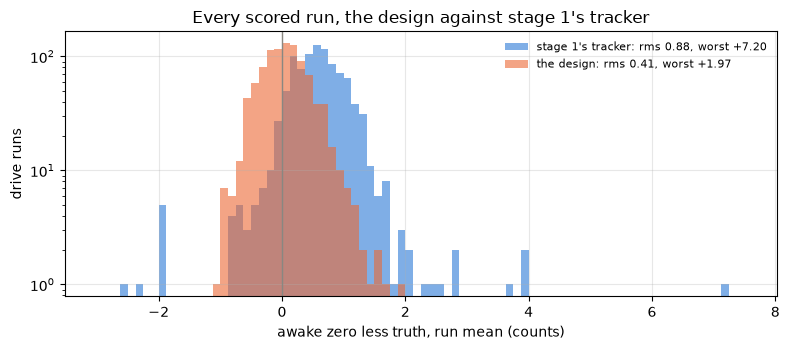

In [68]:
best = seeded("set", 1, **START, coast_raw=True, drive_off=OFF_DAY)
d_best = zr.classes(zr.score(best, STORE), SW, HALF_COUNT_V, LONG_GAP_S)
d_best = d_best[d_best["truth"].notna()]
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(-3, 7.5, 85)          # counts
for d, color, name in ((D_AGE, BLUE, "stage 1's tracker"),
                       (d_best, ORANGE, "the design")):
    st = zr.stats(d["err_mean"])
    ax.hist(d["err_mean"], bins=bins, color=color, alpha=0.6,
            label=f"{name}: rms {st['rms']:.2f}, worst {st['worst']:+.2f}")
ax.axvline(0, color=MUTED, lw=1)
ax.set_yscale("log")
figures.label(ax, x="awake zero less truth, run mean (counts)",
              y="drive runs", title="Every scored run, the design against "
              "stage 1's tracker")
ax.legend(frameon=False, loc="upper right", fontsize=8)
figures.finish(fig)

What you are looking at: the run-mean error of all 975 scored drive runs, stage 1's tracker against the design, on a log count scale. The design's runs sit centered on zero, and the tail of stage 1's tracker past 2 counts, the starts, is gone.

## 9. What stage 5 reads from here

The estimator a firmware runs, as the data asks for it. The state is two zeros as 64-bit floats in counts, their fresh counters in ticks, the rail the awake zero was learned at, the last rail sample, and the running mean of the drive-feed offset. The constants it reads are alpha $2^{-13}$, the stale count of 65535 ticks, the settle count of 32 ticks, the gate of 30 % of the period, the step shape at the rails its identification visited, the seed threshold and the debounce of 32 rail rows. It runs once per control tick, at 20 kHz, and the reading is the crest sample less the awake zero with its fraction.

In [69]:
d_row = DESIGN[(DESIGN["gap"] == "age")].set_index("rule")
dz, s1 = d_row.loc["start rule + constant"], d_row.loc["stage 1"]
best_w = d_best[d_best["cls"] == "warm"]
bias = best_w.groupby(rail_band(best_w["vbus"]), observed=True)["err_mean"]
seed_ev = EV2[EV["e0"].abs() > 1.5]
STAGE5 = [
    ("bias, warm, by rail band (counts)", ", ".join(
        f"{k} V {v:+.2f}" for k, v in bias.mean().items()),
     "the design; stage 1's tracker +0.54 to +0.76"),
    ("scatter, warm (counts sd)", f"{dz['warm_sd']:.2f}",
     "at the truth's own floor"),
    ("noise per tick of the sample (counts sd)",
     f"{TICK_NOISE.iloc[0]['sd']:.2f} asleep, {TICK_NOISE.iloc[1]['sd']:.2f}"
     f" coast, {TICK_NOISE.iloc[2]['sd']:.2f} narrow drive",
     "16-tick pattern 1.0 pp, 1/f low end"),
    ("noise of the zero at 2^-13 (counts)",
     f"{ALPHA.set_index('shift').loc[13, 'z_sd_white']:.3f} white, "
     f"{ALPHA.set_index('shift').loc[13, 'z_sd_2s_coast']:.2f} in a 2 s "
     "coast", "the zero follows the amplifier's wander"),
    ("time constant (s of feed)", f"{TAU_S:.4f}",
     f"corner {1 / (2 * np.pi * TAU_S):.2f} Hz"),
    ("valid: fed share of awake rows", f"{FEED_RULES.iloc[1]['fed_awake']:.2f}",
     f"longest unfed awake stretch {UNFED_S.max():.2f} s"),
    ("hold, 90 % at 1 / 10 / 60 s (counts)", " / ".join(
        f"{HORIZONS.loc[h, 'p90']:.2f}" for h in (1, 10, 60)),
     f"re-seed past {THR_V:.2f} V of rail move"),
    ("start-up to 0.5 counts (s of feed)",
     f"{seed_ev['fed_s_to_0.5'].median():.2f} median, "
     f"{seed_ev['fed_s_to_0.5'].max():.2f} worst",
     f"stage 1's tracker {BIG['fed_s_to_0.5'].median():.2f} median"),
    ("all runs (counts rms, worst)", f"{dz['all_rms']:.2f}, "
     f"{dz['all_worst']:+.2f}",
     f"stage 1's tracker {s1['all_rms']:.2f}, {s1['all_worst']:+.2f}")]
for name, value, note in STAGE5:
    print(f"{name}: {value} ({note})")

bias, warm, by rail band (counts): 3.6 V -0.01, 4.9 V -0.01, 6.0-6.8 V +0.01, 7.0-7.6 V +0.20, >7.8 V +0.78 (the design; stage 1's tracker +0.54 to +0.76)
scatter, warm (counts sd): 0.41 (at the truth's own floor)
noise per tick of the sample (counts sd): 1.06 asleep, 1.11 coast, 1.16 narrow drive (16-tick pattern 1.0 pp, 1/f low end)
noise of the zero at 2^-13 (counts): 0.007 white, 0.09 in a 2 s coast (the zero follows the amplifier's wander)
time constant (s of feed): 0.4096 (corner 0.39 Hz)
valid: fed share of awake rows: 0.91 (longest unfed awake stretch 2.40 s)
hold, 90 % at 1 / 10 / 60 s (counts): 0.59 / 0.81 / 0.95 (re-seed past 0.32 V of rail move)
start-up to 0.5 counts (s of feed): 0.06 median, 0.30 worst (stage 1's tracker 0.78 median)
all runs (counts rms, worst): 0.41, +1.97 (stage 1's tracker 0.88, +7.20)


Warm, the design leaves a bias of -0.01 to +0.20 counts on the rail bands up to 7.6 V and +0.78 over 7.8 V, against +0.54 to +0.76 for stage 1's tracker. The band over 7.8 V holds the fewest runs, and its sweeps most likely open on a seed from the line, whose held-out residual there is -1.63 counts (section 4). The design leaves a scatter of 0.41 counts sd at the truth's own floor. The sample the zero is subtracted from carries 1.06 to 1.16 counts sd per tick with no current, the 16-tick pattern of one count peak to peak and a 1/f low end the zero follows up to its corner at 0.39 Hz. The zero itself adds 0.007 counts of white noise and moves 0.09 counts over a 2 s coast, following the amplifier. The valid flag of the zero is that it has been fed or seeded since the last boot or rail move and is inside the hold bound. On these sweeps 0.91 of the awake rows feed it, and the longest unfed awake stretch, 2.40 s, sits well inside the 60 s bound of 0.95 counts at the 90 % point. Past a rail move of 0.32 V the zero is re-seeded. From a boot or a rail move the design is inside half a count after 0.06 s of feed, 0.30 s at worst, where stage 1's tracker takes 0.78 s.

### The gaps

Each gap with the capture that would close it.

- The rows carry no rail, reference or board temperature channel, so the rail exists only inside a drive and temperature is not tested as a mover of the zero. Any stage 3 schedule re-streamed with `vbus`, `vref_raw` and `ntc_raw`, plus one torque-off and coast series while the board warms on the printer bed rig, gives the step and the asleep zero against the temperature and lets the start rule act before the first drive.
- The step's shape off 4.9 V comes from one capture day, 11-06. Three sweeps with a coast at 3.7, 5.0 and 7.4 V on another day hold the curve out by day.
- The sag's 6.0-6.8 V band sits above the curve that fits every other rail, and its 60 s hold is the widest. One ladder sweep with coasts at 6.0, 6.4 and 6.8 V on the ladder's own supply separates a step that is flat from 6 V from something the sag set does.
- Whether the step follows a rail that sags under the load is not measured. A narrow drive with a series resistor switched in for half the run, with the trough's level either side and a coast after each half, measures it.
- A drive between two truth readings adds 0.40 counts in quadrature. The ladder's schedule with a rest in place of every second rung, at the same spacing, separates what the drive leaves behind from the wander over the longer lag.
- Faster alphas score worse against the tail truth but not against a truth 0.1 s away. A coast of 0.1 s appended to every narrow rung gives every run a truth at both ends.
- Sweeps with no coast, the stalls and most of the load holds, are scored only against the proxy truth. A coast of 0.1 s appended to a stall hold in any later capture scores them.
- Nothing was captured between 80 and 100 % duty, so the off window's floor lies between 240 ticks and none. Three rungs between 80 and 100 % with a coast after each place it.
- The trough's rise under a drive grows with the rail. Stage 1's dummy-load trough at two rails and the same duty separates the amplifier's settle from the supply.
- The 3.3 V laps moved both zeros by 14.5 counts. The asleep baseline streamed with `vref_raw` while the supply steps from 3.3 to 3.8 V in 50 mV finds the system rail where the regulator lets go.
- The zero during a wide drive and over a wide drive longer than 2.4 s is not in the data. A hold at 60 % duty for 10 s and 60 s with a coast after each bounds it.

### The result file

Every number in it comes from one servo, mg90-d, on one board, dev-v006-2A-D, over four days of stage 3 captures. Repeatability here means across days, rails and experiments of this pair, not across servos. Each is a candidate until a second servo repeats it. The scores are the float tracker's, 0.0625 counts above the integer port's where they are means of the zero.

In [70]:
q, pm = results.quantity, results.pm
w1, cls_t = CLASS_TABLE.loc["warm, age"], CLASS_TABLE
fr = FEED_RULES.set_index("rule")
f30 = fr[fr["form"] == "float"].loc["duty <= 30 % (stage 1)"]
cfit = FITS.set_index(["set", "model"])
c_i, c_s = cfit.loc[("coast truth", "i")], cfit.loc[("stall + loaded hold",
                                                     "i")]
QUANTITIES = {
    "truth_share_of_sweeps": q(SW["truth"].notna().mean(), unit="share"),
    "truth_floor_counts": q(TRUTH_RNG.median(), unit="counts"),
    "warm_error_counts_rms": q(w1["rms"], w1["lo"], w1["hi"], "counts"),
    "warm_error_mean_counts": q(w1["mean"], unit="counts"),
    "warm_error_sd_counts": q(w1["sd"], unit="counts"),
    "rail_moved_error_counts_rms": q(cls_t.loc["rail moved, age", "rms"],
                                     cls_t.loc["rail moved, age", "lo"],
                                     cls_t.loc["rail moved, age", "hi"],
                                     "counts"),
    "cold_error_counts_rms": q(cls_t.loc["cold, age", "rms"],
                               cls_t.loc["cold, age", "lo"],
                               cls_t.loc["cold, age", "hi"], "counts"),
    "all_error_counts_rms": q(cls_t.loc["all, age", "rms"], unit="counts"),
    "worst_error_counts": q(cls_t.loc["all, age", "worst"], unit="counts"),
    "trough_current_share": pm(c_i["b1"], c_i["b1_se"], "share"),
    "trough_current_share_stall": pm(c_s["b1"], c_s["b1_se"], "share"),
    "feed_gate_pct": q(zr.GATE_REC_PCT, unit="%"),
    "feed_gate_clean_to_pct": q(80, unit="%"),
    "feed_share_drive_rows": q(f30["fed_drive"], unit="share"),
    "feed_share_awake_rows": q(f30["fed_awake"], unit="share"),
    "stall_hold_error_counts_rms": q(f30["stall_hold_rms"], unit="counts"),
    "coast_only_moved_cold_counts_rms": q(
        fr.loc["coast + torque off only", "moved_cold_rms"], unit="counts"),
}
print(len(QUANTITIES), "keys")

17 keys


In [71]:
oa = OFFSETS.set_index(["state", "by"]).loc[[("asleep", "all"),
                                              ("coast tail", "all")]]
co_out = fr.loc[f"same, drive feed less {DRIVE_OFF_IN:.2f}"]
QUANTITIES.update({
    "column_offset_coast_counts": pm(oa["mean"].iat[1], oa["sd"].iat[1],
                                     "counts"),
    "column_offset_asleep_counts": pm(oa["mean"].iat[0], oa["sd"].iat[0],
                                      "counts"),
    "trough_drive_over_coast_counts": pm(RISE[0], RISE[2], "counts"),
    "warm_error_constant_out_counts_rms": q(co_out["warm_rms"],
                                            co_out["lo"], co_out["hi"],
                                            "counts"),
    "awake_step_slope_counts_per_v": pm(LINE["slope"], LINE["slope_se"],
                                        "counts/V"),
    "awake_step_intercept_counts": pm(LINE["intercept"],
                                      LINE["intercept_se"], "counts"),
    "awake_step_residual_counts": q(LINE_SD, unit="counts"),
    "float_minus_integer_counts": q(
        FLOAT_INT.iloc[0]["mean"], FLOAT_INT.iloc[0]["p01"],
        FLOAT_INT.iloc[0]["p99"], "counts"),
    "float_minus_integer_max_counts": q(FLOAT_INT.iloc[0]["max"],
                                        unit="counts"),
    "rounded_zero_extra_counts_rms": q(FLOAT_INT.iloc[2]["rms"],
                                       unit="counts"),
    "float32_state_rms_counts": q(FLOAT_INT.iloc[3]["rms"], unit="counts"),
    "start_error_counts": {
        "boot": q(E_BOOT, unit="counts"),
        "rail_move_median": q(E_MOVE, unit="counts"),
        "worst": q(BIG["e0"].abs().max(), unit="counts")},
    "settle_to_1_count_fed_s": q(BIG["fed_s_to_1"].median(),
                                 BIG["fed_s_to_1"].min(),
                                 BIG["fed_s_to_1"].max(), "s"),
    "settle_to_half_count_fed_s": q(BIG["fed_s_to_0.5"].median(),
                                    BIG["fed_s_to_0.5"].min(),
                                    BIG["fed_s_to_0.5"].max(), "s"),
    "tau_s": q(TAU_S, unit="s"),
})
print(len(QUANTITIES), "keys")

32 keys


In [72]:
sbr = STEP_BY_RAIL["step"]
keys = {"3.6": "3v6", "4.9": "4v9", "6.0-6.8": "6v0_6v8",
        "7.0-7.6": "7v0_7v6", ">7.8": "over_7v8"}
rs = R.loc["seed at boot + rail moved"]
QUANTITIES.update({
    "awake_step_by_rail_counts": {
        keys[k]: q(v, unit="counts") for k, v in sbr.items()},
    "step_line_heldout_rms_counts": q(SD_LINE, unit="counts"),
    "step_curve_heldout_rms_counts": q(np.sqrt((FITS_STEP[("set", 2)][2][
        "res_out"].dropna() ** 2).mean()), unit="counts"),
    "step_heldout_by": "capture set",
    "seed_rail_threshold_v": q(THR_V, 0.2, 1.0, "V"),
    "held_zero_sd_counts": q(SD_HELD, unit="counts"),
    "seed_debounce_ticks": q(zr.ZERO_SETTLE_TICKS, unit="ticks"),
    "start_rule_events_rms_counts": q(rs["ev_rms"], rs["ev_lo"],
                                      rs["ev_hi"], "counts"),
    "stage1_events_rms_counts": q(R.loc["stage 1, no start rule", "ev_rms"],
                                  unit="counts"),
    "start_rule_start_error_rms_counts": q(rs["start_rms"], unit="counts"),
    "start_rule_warm_cost_counts": q(rs["d_warm"], rs["d_warm_lo"],
                                     rs["d_warm_hi"], "counts"),
    "start_rule_settle_to_half_count_fed_s": q(
        seed_ev["fed_s_to_0.5"].median(), None,
        seed_ev["fed_s_to_0.5"].max(), "s"),
})
for key, name in (("seed_on_stale_line_warm_cost_counts",
                   "seed at boot + stale + rail moved (line)"),
                  ("fast_alpha_stale_warm_cost_counts",
                   "fast 2^-10, 4096 ticks, stale")):
    x = R.loc[name]
    QUANTITIES[key] = q(x["d_warm"], x["d_warm_lo"], x["d_warm_hi"],
                        "counts")
print(len(QUANTITIES), "keys")

46 keys


In [73]:
H = HORIZONS
hz = {1: "1s", 10: "10s", 60: "60s"}
st_h = HOURS[(HOURS["what"] == "step") & (HOURS["lag_lo"] == 3600)].iloc[0]
duty_m = MOVERS.set_index("terms").loc["duty_prev"]
tn = TICK_NOISE[TICK_NOISE["column"] == "trough"].set_index("state")
lw = LOW.set_index(["state", "column"])
QUANTITIES.update({
    "hold_p90_counts": {hz[h]: q(H.loc[h, "p90"], H.loc[h, "p90_lo"],
                                 H.loc[h, "p90_hi"], "counts") for h in hz},
    "hold_median_counts": {hz[h]: q(H.loc[h, "median"], unit="counts")
                           for h in hz},
    "hold_worst_counts": {hz[h]: q(H.loc[h, "worst"], unit="counts")
                          for h in hz},
    "hold_pairs": {hz[h]: q(H.loc[h, "pairs"], unit="pairs") for h in hz},
    "step_hold_2h_p90_counts": q(st_h["p90"], unit="counts"),
    "truth_floor_p90_counts": q(FLOOR["p90"], unit="counts"),
    "zero_per_rail_volt_counts": q(RAIL_K, unit="counts/V"),
    "truth_per_unit_duty_counts": pm(duty_m["duty_prev"],
                                     duty_m["duty_prev_se"], "counts"),
    "longest_unfed_awake_s": q(UNFED_S.max(), unit="s"),
    "asleep_shift_3v3_laps_counts": q(EPISODE_SHIFT, unit="counts"),
    "trough_sd_per_tick_counts": {
        k.replace(" ", "_"): q(tn.loc[k, "sd"], tn.loc[k, "sd_10"],
                               tn.loc[k, "sd_90"], "counts")
        for k in ("asleep", "coast", "narrow drive")},
    "trough_fold16_pp_counts": q(tn.loc["coast", "fold_pp"],
                                 tn["fold_pp"].min(), tn["fold_pp"].max(),
                                 "counts"),
    "low_end_over_white": {
        k: q(lw.loc[("coast", "trough"), b], unit="ratio") for k, b in
        (("1hz", "0.5-2 Hz"), ("10hz", "5-15 Hz"), ("100hz", "50-200 Hz"))},
    "crest_less_trough_low_end_over_white": q(
        lw.loc[("coast", "raw less trough"), "0.5-2 Hz"], unit="ratio"),
    "alpha_flat_band_shift": [12, 14],
})
print(len(QUANTITIES), "keys")

61 keys


In [74]:
A = ALPHA.set_index("shift")
QUANTITIES["alpha_scan"] = {
    f"shift_{sh}": {
        "tau_s": q(A.loc[sh, "tau_s"], unit="s"),
        "zero_noise_white_counts": q(A.loc[sh, "z_sd_white"], unit="counts"),
        "zero_move_2s_coast_counts": q(A.loc[sh, "z_sd_2s_coast"],
                                       unit="counts"),
        "warm_rms_counts": q(A.loc[sh, "warm_rms"], A.loc[sh, "warm_lo"],
                             A.loc[sh, "warm_hi"], "counts"),
        "warm_rms_full_counts": q(A.loc[sh, "full_warm_rms"],
                                  A.loc[sh, "full_warm_lo"],
                                  A.loc[sh, "full_warm_hi"], "counts"),
        "close_boot_s": q(A.loc[sh, "close_boot_s"], unit="s")}
    for sh in SHIFTS}
print(len(QUANTITIES), "keys")

62 keys


In [75]:
CT = CONST_T.set_index("rule")
hd_row = CT.loc["constant, held out by day"]
QUANTITIES.update({
    "drive_feed_offset_counts": q(OFF["e"].mean(),
                                  FOLDS_DAY["off"].min(),
                                  FOLDS_DAY["off"].max(), "counts"),
    "drive_feed_offset_se_counts": q(OFF["e"].std() / np.sqrt(len(OFF)),
                                     unit="counts"),
    "constant_out_heldout_warm_rms_counts": q(hd_row["rms"], hd_row["lo"],
                                              hd_row["hi"], "counts"),
    "constant_out_fold_rms_counts": {
        r.day: q(r.rms, unit="counts") for r in CONST_FOLDS.itertuples()},
    "offset_rail_slope_counts_per_v": pm(OFF_LINE[1], OFF_LINE[2],
                                         "counts/V"),
    "constant_self_measured_warm_rms_counts": q(
        CT.loc["constant from past sweeps only", "rms"],
        CT.loc["constant from past sweeps only", "lo"],
        CT.loc["constant from past sweeps only", "hi"], "counts"),
    "design_all_runs_rms_counts": q(dz["all_rms"], unit="counts"),
    "design_all_runs_worst_counts": q(dz["all_worst"], unit="counts"),
    "design_events_rms_counts": q(dz["ev_rms"], dz["ev_lo"], dz["ev_hi"],
                                  "counts"),
    "design_warm_rms_counts": q(dz["warm_rms"], dz["warm_lo"],
                                dz["warm_hi"], "counts"),
    "stage1_all_runs_rms_counts": q(s1["all_rms"], unit="counts"),
    "stage1_all_runs_worst_counts": q(s1["all_worst"], unit="counts"),
    "stage5_table": [dict(quantity=a, value=b, note=c) for a, b, c in STAGE5],
})
print(len(QUANTITIES), "keys")

75 keys


In [76]:
GAPS = [
    dict(gap="no rail, reference or temperature channel in the rows",
         capture="a stage 3 schedule re-streamed with vbus, vref_raw and "
                 "ntc_raw; a torque-off and coast series while the board "
                 "warms"),
    dict(gap="the step's shape off 4.9 V rests on one day",
         capture="three sweeps with a coast at 3.7, 5.0 and 7.4 V on "
                 "another day"),
    dict(gap="the 6.0-6.8 V band sits above the curve",
         capture="a ladder sweep with coasts at 6.0, 6.4 and 6.8 V"),
    dict(gap="the step under a rail that sags with the load",
         capture="a narrow drive with a series resistor for half the run, "
                 "a coast after each half"),
    dict(gap="a drive between two readings adds 0.40 counts",
         capture="the ladder with a rest in place of every second rung"),
    dict(gap="fast alphas against a far truth",
         capture="a 0.1 s coast after every narrow rung"),
    dict(gap="stalls and loaded holds scored on the proxy truth",
         capture="a 0.1 s coast after a stall hold"),
    dict(gap="nothing between 80 and 100 % duty",
         capture="rungs at 85, 90 and 95 % with a coast after each"),
    dict(gap="the trough's rise under a drive grows with the rail",
         capture="stage 1's dummy-load trough at two rails, same duty"),
    dict(gap="the 3.3 V laps moved both zeros",
         capture="the asleep baseline with vref_raw while the supply steps "
                 "3.3 to 3.8 V in 50 mV"),
    dict(gap="the zero during and after a wide drive over 2.4 s",
         capture="holds at 60 % duty for 10 and 60 s, a coast after each")]
QUANTITIES["gaps"] = GAPS
print(len(QUANTITIES), "keys,", len(GAPS), "gaps")

76 keys, 11 gaps


In [77]:
NOTES = (
    "stage 4 current-zero of mg90-d on dev-v006-2A-D, no capture of its "
    "own: every stage 3 sweep of the pair in time order (521 sweeps, "
    "four days) through oscnb.sweeps.row_store and oscnb.zero. One "
    "servo, one board. Truth: the crest column's mean over the last "
    "100 ms of a coast of 100 ms past its settle ticks; a drive run takes "
    "the tail nearest its first row; 244 sweeps carry one. Error: the "
    "float tracker's awake zero (64-bit state, the estimator of record; "
    "the integer Q16 port reads 0.0625 lower) less the truth, the run "
    "mean unless named. Classes: cold after 200 stale periods of rest, "
    "rail moved past half a count of stage 1's step line, else warm. "
    "Brackets: 95 % from resampling sweeps (2000 draws, seed 1); "
    "paired differences over the same runs. truth_floor: median range "
    "of a sweep's tails over sweeps with two or more. Feed: duty gate "
    "30 %, settled coast, torque off; the trough share fits OLS at 30 % "
    "or narrower, +/- se. Unit 1's gate-width rows are float, its "
    "current-gate and share rows the integer port. ")
NOTES += (
    "Start rule: seed awake = asleep + step(rail) at boot and when the "
    "rail moves past seed_rail_threshold_v (sqrt(line held-out rms^2 - "
    "held zero sd^2) / slope, bounds the flat band) for 32 rail rows, "
    "the rail read off the driven terminal; step line held out by "
    "capture set. Hold: |difference| of two 100 ms truth readings on one "
    "rail (within 0.1 count of step), 1 s inside one coast, 10 and 60 s "
    "tail pairs; bounds of p90 by resampling the earlier sweep. Noise: "
    "settled stretches, Welch 2048 rows; low end 16384 rows on coasts of "
    "0.8 s and more. Constant: per sweep the narrow drives' trough less "
    "its coast truth; the coast fed from the crest column; held out by "
    "day (bounds of drive_feed_offset: the four folds). Design: start "
    "rule + constant held out by day, all 975 runs, age gap model. "
    "results/<pair>.step.csv: the step by rail band with the line and "
    "curve held out by capture set; results/<pair>.alpha.csv: the zero "
    "against alpha 2^-9 to 2^-15.")
path = results.write(STAGE, EXPERIMENT, PAIR_DIR, pair=PAIR, notes=NOTES,
                     **QUANTITIES)
written = results.read(STAGE, EXPERIMENT, pair=PAIR)
print("wrote", path, "with", len(QUANTITIES), "keys, capture",
      written["capture"])

wrote stages/4-estimators/current-zero/results/mg90-d__dev-v006-2A-D.json with 76 keys, capture telemetry/mg90-d__dev-v006-2A-D


In [78]:
base = results.path(STAGE, EXPERIMENT, pair=PAIR)
STEP_PATH = base.with_suffix(".step.csv")
ALPHA_PATH = base.with_suffix(".alpha.csv")
step = STEP_BY_RAIL.reset_index().rename(columns={"band": "rail_band"})
for by, deg, name in ((None, 1, "line"), (None, 2, "curve")):
    co = FITS_STEP[(by, deg)][1].iloc[0]
    step[f"{name}_in_sample"] = sum(co.get(f"c{i}", 0.0) * step["rail"] ** i
                                    for i in range(deg + 1))
    for i in range(deg + 1):
        step[f"{name}_c{i}"] = co[f"c{i}"]
step.to_csv(STEP_PATH, index=False, float_format="%.4f")
ALPHA[["shift", "tau_s", "corner_hz", "z_sd_white", "z_sd_spectrum",
       "z_sd_2s_coast", "read_sd_coast", "close_boot_s", "close_move_s",
       "close_seeded_s", "warm_rms", "warm_lo", "warm_hi", "warm_mean",
       "d13", "seed_warm_rms", "seed_d13", "full_warm_rms", "full_warm_lo",
       "full_warm_hi", "full_warm_mean", "full_d13", "full_end_fed_sd",
       "full_end_held_sd"]].to_csv(ALPHA_PATH, index=False,
                                   float_format="%.4f")
for p in (STEP_PATH, ALPHA_PATH):
    back = pd.read_csv(p)
    print(f"wrote {results.rel(p)}: {len(back)} rows, columns "
          f"{', '.join(back.columns)}")
flat = [{"key": k, **v} for k, v in written.items()
        if isinstance(v, dict) and "value" in v]
print(pd.DataFrame(flat).round(3).to_string(index=False))

wrote stages/4-estimators/current-zero/results/mg90-d__dev-v006-2A-D.step.csv: 5 rows, columns rail_band, n, rail, step, step_sd, line_res, line_res_sd, curve_res, curve_res_sd, line_in_sample, line_c0, line_c1, curve_in_sample, curve_c0, curve_c1, curve_c2
wrote stages/4-estimators/current-zero/results/mg90-d__dev-v006-2A-D.alpha.csv: 7 rows, columns shift, tau_s, corner_hz, z_sd_white, z_sd_spectrum, z_sd_2s_coast, read_sd_coast, close_boot_s, close_move_s, close_seeded_s, warm_rms, warm_lo, warm_hi, warm_mean, d13, seed_warm_rms, seed_d13, full_warm_rms, full_warm_lo, full_warm_hi, full_warm_mean, full_d13, full_end_fed_sd, full_end_held_sd
                                   key  value     lo     hi     unit
                 truth_share_of_sweeps  0.468    NaN    NaN    share
                    truth_floor_counts  0.396    NaN    NaN   counts
                 warm_error_counts_rms  0.730  0.684  0.778   counts
                warm_error_mean_counts  0.584    NaN    NaN   counts
   